# Ejercicio Práctico — Semana 3: Emociones en texto: NLP, clasificación y procesamiento distribuido

**Asignatura:** Inteligencia Artificial: Data Mining II — Maestría en Ciencias de Datos y Máquinas de Aprendizaje, mención IA (UIDE)
**Docente:** Miguel Angel Rosero Aguas
**Cubre:** Sesión 1 — Big Data con PySpark: Online Retail II  /  Sesión 2 — NLP, spaCy, LDA y Spark MLlib
**Grupo N.º:** 3

| # | Integrante | Rol en el equipo |
|---|---|---|
| 1 | Diana Tandalla | Líder de Proyecto / Analista de Datos |
| 2 | Wilson Paredes | Desarrollador de Grafos (NetworkX) |
| 3 | Alexander Luna | Analista de Algoritmos y Comunidades |
| 4 |                | Especialista en IA y Recomendación |

## Índice

1. [Carga, limpieza y exploración del corpus](#fase-1)
2. [Análisis lingüístico con spaCy: POS y NER](#fase-2)
3. [Modelado de temas (LDA)](#fase-3)
4. [Clasificación clásica: Naive Bayes y SVM](#fase-4)
5. [Red neuronal recurrente (RNN)](#fase-5)
6. [Experimento: número de clases](#fase-6)
7. [Big Data: PySpark, MLlib y MapReduce](#fase-7)
8. [Desafío y evaluación de alternativas](#fase-8)
9. [Tendencias: BERTopic, LLM en el pipeline y Parquet](#fase-9)
10. [Fase final: aplicación al entorno profesional](#fase-final)

## Estructura del ejercicio

Este notebook va con la guía **Ejercicio_Practico_Semana3_Guia.docx**: el código y los gráficos se hacen aquí; en la guía responden por escrito
la **pregunta de cada fase** (la misma que aparece abajo de cada título) y la fase final individual.

| Bloque | Fases | Qué entregan |
|---|---|---|
| Datos y exploración | 1–3 | código + conclusión en el notebook; respuesta en la guía |
| Modelado y análisis | 4–7 | código + conclusión en el notebook; respuesta en la guía |
| Desafío y tendencias | 8–9 | evidencia en el notebook; respuesta en la guía |
| Aplicación profesional | final | una respuesta por integrante (notebook y guía) |

**Entrega en Canvas:** este notebook ejecutado y la guía completada (Word o PDF).

## Contexto

El área de experiencia del cliente de una empresa recibe miles de mensajes al día y quiere detectar automáticamente la emoción de cada uno para priorizar la atención. Antes de invertir, les pide un estudio con un corpus público de tweets etiquetados con 13 emociones: qué dice el texto (análisis lingüístico y temas), qué tan bien se puede clasificar la emoción según cuántas emociones se distingan, y si hace falta una plataforma distribuida (Spark/Hadoop) para su volumen.

**Dataset:** Emotion Detection from Text (Kaggle, pashupatigupta): https://www.kaggle.com/datasets/pashupatigupta/emotion-detection-from-text (tweet_emotions.csv: 40 000 tweets, columnas tweet_id, sentiment, content)

## Desafío

1) Recomendar la **granularidad de emociones** (número de clases) que el área puede usar con confianza, con evidencia del experimento de clases y una línea base. 2) Recomendar el **modelo** (Naive Bayes, SVM o RNN) con su costo y su desempeño. 3) Estimar si su volumen justifica **Spark** y cómo se desplegaría (HDFS/S3, clúster en AWS), con evidencia del pipeline en PySpark. 4) Declarar una limitación seria del dataset y una implicación ética.

> **Formato de entrega:** un único `.ipynb` ejecutado. Código limpio y comentado. Antes de cada gráfico,
> una línea que diga qué se analiza; después, la conclusión de negocio. Nombre del archivo:
> `grupoN_Semana3_Ejercicio.ipynb`.

In [ ]:
# ===== Entorno: el mismo notebook corre en Google Colab y en local =====
import importlib, importlib.util, os, shutil, subprocess, sys, urllib.request   # utilidades: instalar paquetes, rutas y descargas
from pathlib import Path                            # rutas iguales en Windows, Linux y Colab

EN_COLAB = "google.colab" in sys.modules           # True si estamos dentro de Colab
print("Entorno:", "Google Colab" if EN_COLAB else "local", "| Python", sys.version.split()[0])   # dónde corre y qué Python

# Instalamos solo los paquetes que falten. El nombre en pip no siempre es el del import:
# ej.: pip install scikit-learn -> import sklearn; nx-parallel -> nx_parallel
IMPORT_DE = {"scikit-learn": "sklearn", "sentence-transformers": "sentence_transformers",   # nombre en pip -> nombre del import
             "delta-spark": "delta", "python-calamine": "python_calamine",   # instaladores y lectores de Excel
             "python-louvain": "community", "imbalanced-learn": "imblearn"}   # comunidades y desbalance de clases
for pip_nombre in ['pyspark', 'spacy', 'kagglehub', 'bertopic', 'sentence-transformers']:   # paquetes que necesita esta práctica
    base = pip_nombre.split("==")[0].split(">=")[0]                    # ej.: "networkx>=3.7" -> "networkx"
    modulo = IMPORT_DE.get(base, base.replace("-", "_"))   # nombre del import. Ej.: nx-parallel -> nx_parallel
    if importlib.util.find_spec(modulo) is None:   # solo si NO está instalado (Colab ya trae muchos)
        r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_nombre])   # Colab y venv con pip
        if r.returncode != 0 and shutil.which("uv"):                   # venv creado con uv (no trae pip)
            r = subprocess.run(["uv", "pip", "install", "-q", "--python", sys.executable, pip_nombre])   # instala con uv en este mismo Python
        if r.returncode != 0:   # ni pip ni uv pudieron instalarlo
            raise RuntimeError(f"Instala '{pip_nombre}' en este entorno (pip/uv) y vuelve a ejecutar")   # error explícito con la acción a seguir
        importlib.invalidate_caches()                                  # para que el import vea el paquete recién instalado

# Spark corre sobre la JVM: en Colab instalamos Java 17; en local debe existir JAVA_HOME
if EN_COLAB and not os.environ.get("JAVA_HOME"):   # solo en Colab y si Java aún no está
    subprocess.run("apt-get install -y -qq openjdk-17-jdk-headless > /dev/null", shell=True, check=True)   # instala Java 17 sin mensajes (tarda ~1 min)
    os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"   # dónde lo deja apt en Colab
if not EN_COLAB and not os.environ.get("JAVA_HOME") and shutil.which("java") is None:   # local sin JAVA_HOME ni java en el PATH
    # Buscamos un JDK 17 en rutas típicas. Ej.: ~/opt/jdk17 (WSL), /usr/lib/jvm/java-17-openjdk-amd64 (Ubuntu)
    import glob   # glob busca rutas con comodines. Ej.: /usr/lib/jvm/*17*
    for jdk in [str(Path.home() / "opt" / "jdk17"), *glob.glob("/usr/lib/jvm/*17*"),   # rutas candidatas de un JDK 17
                *glob.glob(r"C:\Program Files\Eclipse Adoptium\jdk-17*")]:   # Windows con Temurin 17
        if Path(jdk, "bin").exists():   # es un JDK si tiene la carpeta bin
            os.environ["JAVA_HOME"] = jdk                                    # Spark lo lee al arrancar
            os.environ["PATH"] = str(Path(jdk, "bin")) + os.pathsep + os.environ["PATH"]   # el comando java queda disponible
            break   # se usa el primero que exista
if not EN_COLAB and not os.environ.get("JAVA_HOME") and shutil.which("java") is None:   # no se encontró ningún JDK
    raise RuntimeError("Spark necesita Java 17: instálalo (por ejemplo, Eclipse Temurin 17), define JAVA_HOME "   # sin Java, Spark no arranca
                       "y reinicia el kernel")   # acción para corregirlo
print("JAVA_HOME:", os.environ.get("JAVA_HOME", "(java en el PATH)"))   # confirma qué Java usará Spark
# Los workers de Spark deben usar el MISMO Python que este notebook (si no: PYTHON_VERSION_MISMATCH)
os.environ["PYSPARK_PYTHON"] = os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable   # mismo Python en driver y workers
# Carpeta de datos relativa: en Colab es /content/data, en local ./data
DATA = Path("data"); DATA.mkdir(exist_ok=True)   # crea la carpeta si no existe

def descargar(url, nombre):   # Ej.: descargar(URL, "telco.csv") -> data/telco.csv
    # Descarga una sola vez; si el archivo ya existe, no vuelve a bajarlo
    destino = DATA / nombre   # ruta local del archivo. Ej.: data/telco.csv
    if not destino.exists():   # descarga solo la primera vez
        print("Descargando", nombre, "...")   # aviso de progreso
        urllib.request.urlretrieve(url, destino)   # descarga el archivo en data/
    return destino   # devuelve la ruta para usarla después

ARCHIVOS = [   # lista de (url, nombre) que usa esta práctica

]
for url, nombre in ARCHIVOS:   # descarga cada archivo
    print(nombre, "->", round(descargar(url, nombre).stat().st_size / 1e6, 2), "MB")   # y muestra su tamaño en MB

Entorno: local | Python 3.13.18
JAVA_HOME: /usr/lib/jvm/java-21-openjdk-amd64


In [ ]:
# ===== Estilo de gráficos (principios de Tufte): alta proporción dato-tinta, un solo color de acento =====
import matplotlib.pyplot as plt                     # gráficos
from cycler import cycler                           # orden de colores por defecto
TINTA, ACENTO, GRIS = "#14323F", "#6E5BD6", "#B7C3C9"     # tokens del módulo; ACENTO = color de esta semana
plt.rcParams.update({   # estilo por defecto de todos los gráficos
    "axes.spines.top": False, "axes.spines.right": False,    # sin marco: solo los ejes necesarios
    "axes.grid": False, "axes.edgecolor": GRIS,              # sin rejilla (las etiquetas dicen el valor)
    "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlecolor": TINTA,   # títulos a la izquierda y en negrita
    "axes.prop_cycle": cycler(color=[TINTA, ACENTO, GRIS, "#5B6B73"]),
    "font.size": 12, "legend.frameon": False, "figure.dpi": 110,   # letra legible, leyenda sin caja, nitidez
})
# Regla práctica: pinten con ACENTO solo el dato que quieren que el lector mire; el resto en GRIS.

<a id="fase-1"></a>
## Fase 1: Carga, limpieza y exploración del corpus

Paso 1 del enunciado. Carguen el CSV, revisen duplicados, longitud de los textos y la distribución de las 13 emociones (¿qué tan desbalanceada está? ¿qué significa la etiqueta `empty`?). Limpien menciones, URLs y entidades HTML, y **documenten** cada decisión de limpieza.

> **Pregunta de la guía:** Duplicados, longitud media y distribución de las 13 emociones. ¿Qué significa «empty» y qué hicieron con ella?

**Qué analizamos:** la calidad del archivo `tweet_emotions.csv` (duplicados, textos vacíos, conflictos de etiqueta), la limpieza necesaria para un corpus de tweets (menciones, URLs, entidades HTML) y qué tan desbalanceadas están las 13 emociones.

pandas 3.0.5 | scikit-learn 1.9.1 | numpy 2.5.3


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Fuente: respaldo GitHub (Kaggle no disponible: ProxyError) | filas x columnas: (40000, 3)
     tweet_id sentiment                                                                                       content
0  1956967341     empty  @tiffanylue i know  i was listenin to bad habit earlier and i started freakin at his part =[
1  1956967666   sadness                                  Layin n bed with a headache  ughhhh...waitin on your call...
2  1956967696   sadness                                                           Funeral ceremony...gloomy friday...
filas originales                      40000
nulos (cualquier columna)                 0
tweet_id duplicados                       0
textos (content) duplicados             173
  con la MISMA emoción                   91
  con emoción DISTINTA (conflicto)       82



Tras limpieza: 39,750 tweets (250 eliminados: 173 duplicados + 77 vacíos)

Longitud (palabras): media 12.7 | mediana 12.0 | p95 25.0 | máx 34
Desbalance: mayor/menor = 8541 / 110 = 77.6 veces
Ejemplos de "empty" (etiqueta sin emoción clara):
0     i know i was listenin to bad habit earlier and...
44    middle school and elem. High schools will rema...
52                         hey yu lil fucker i textd yu


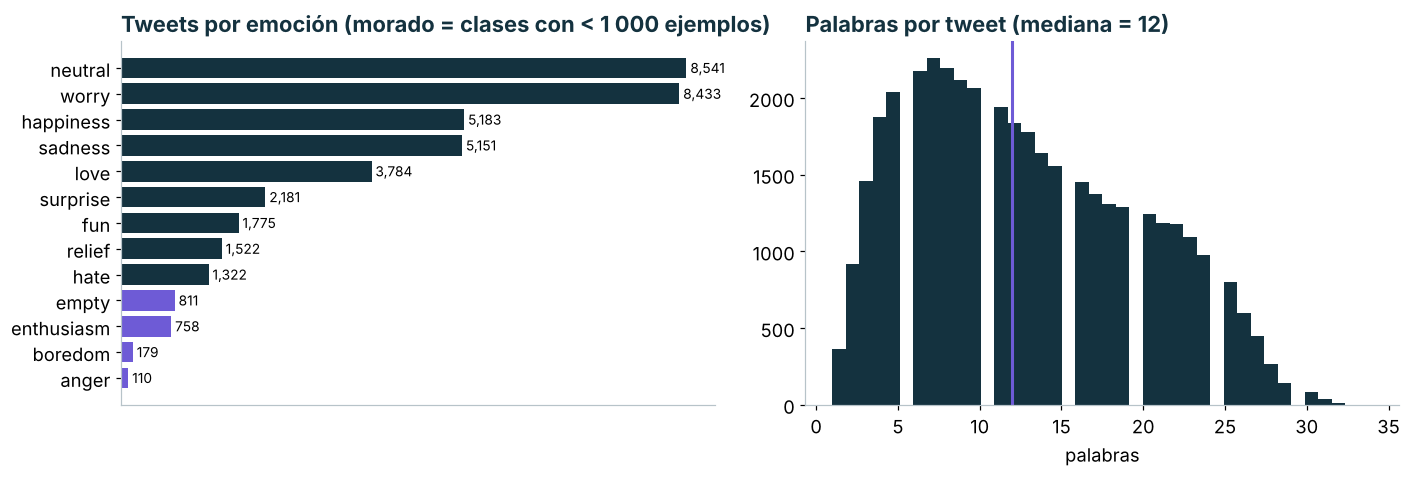

In [ ]:
# ===== Fase 1: carga, calidad de datos y limpieza documentada =====
import html, re, time                                 # html: entidades &amp;; re: menciones y URLs; time: cronómetros
import numpy as np, pandas as pd, sklearn
SEMILLA = 42
print('pandas', pd.__version__, '| scikit-learn', sklearn.__version__, '| numpy', np.__version__)

# Fuente oficial: Kaggle (kagglehub). Respaldo: el MISMO dataset (CrowdFlower, 40 000 tweets y 13 emociones)
# publicado en GitHub como text_emotion.csv; trae una columna extra (author) que descartamos para igualar el esquema.
try:
    import kagglehub
    ruta = kagglehub.dataset_download('pashupatigupta/emotion-detection-from-text')
    df_raw = pd.read_csv(f'{ruta}/tweet_emotions.csv')
    fuente = 'Kaggle (kagglehub)'
except Exception as e:                                # sin acceso a Kaggle: mismo archivo desde GitHub
    url = 'https://raw.githubusercontent.com/tlkh/text-emotion-classification/master/dataset/original/text_emotion.csv'
    df_raw = pd.read_csv(descargar(url, 'tweet_emotions.csv'))
    df_raw = df_raw[['tweet_id', 'sentiment', 'content']]          # mismo esquema que el CSV de Kaggle
    fuente = f'respaldo GitHub (Kaggle no disponible: {type(e).__name__})'
print('Fuente:', fuente, '| filas x columnas:', df_raw.shape)
print(df_raw.head(3).to_string())

# --- Calidad: nulos, duplicados y conflictos de etiqueta ---
calidad = pd.Series({
    'filas originales': len(df_raw),
    'nulos (cualquier columna)': int(df_raw.isna().any(axis=1).sum()),
    'tweet_id duplicados': int(df_raw['tweet_id'].duplicated().sum()),
    'textos (content) duplicados': int(df_raw['content'].duplicated().sum()),
    '  con la MISMA emoción': int(df_raw.duplicated(['content', 'sentiment']).sum()),
    '  con emoción DISTINTA (conflicto)': int(df_raw['content'].duplicated().sum() - df_raw.duplicated(['content', 'sentiment']).sum()),
})
print(calidad.to_string())

# --- Limpieza documentada (cada decisión, su porqué) ---
# 1) quitamos duplicados exactos de texto: si el mismo tweet cayera en train y test inflaría las métricas (fuga)
#    (lección de la semana 1: separar filas copiadas de filas nuevas); con etiquetas en conflicto conservamos la 1.ª
# 2) deshacemos entidades HTML (&amp; -> &, &quot; -> ") porque son ruido de exportación, no lenguaje
# 3) sustituimos URLs por nada y @menciones por nada: no cargan emoción y son casi únicas (vocabulario inútil)
# 4) colapsamos espacios repetidos y quitamos tweets que quedaron vacíos tras limpiar
df = df_raw.drop_duplicates('content', keep='first').copy()
df['texto_limpio'] = (df['content'].map(html.unescape)
                      .str.replace(r'https?://\S+|www\.\S+', ' ', regex=True)     # URLs fuera
                      .str.replace(r'@\w+', ' ', regex=True)                      # menciones fuera
                      .str.replace(r'\s+', ' ', regex=True).str.strip())          # espacios normalizados
vacios = (df['texto_limpio'] == '').sum()
df = df[df['texto_limpio'] != ''].reset_index(drop=True)
print(f"\nTras limpieza: {len(df):,} tweets ({len(df_raw) - len(df):,} eliminados: "
      f"{int(calidad['textos (content) duplicados'])} duplicados + {vacios} vacíos)")

df['n_palabras'] = df['texto_limpio'].str.split().str.len()
dist = df['sentiment'].value_counts()
print('\nLongitud (palabras): media', round(df['n_palabras'].mean(), 1), '| mediana', df['n_palabras'].median(),
      '| p95', df['n_palabras'].quantile(0.95), '| máx', df['n_palabras'].max())
print('Desbalance: mayor/menor =', dist.iloc[0], '/', dist.iloc[-1], '=', round(dist.iloc[0] / dist.iloc[-1], 1), 'veces')
print('Ejemplos de "empty" (etiqueta sin emoción clara):')
print(df.loc[df['sentiment'] == 'empty', 'texto_limpio'].head(3).to_string())

# --- Gráfico. Qué analizamos: cuán desbalanceadas están las 13 emociones y cuánto mide un tweet ---
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
d = dist.sort_values()
axs[0].barh(d.index, d.values, color=[ACENTO if v < 1000 else TINTA for v in d.values])
for y, v in enumerate(d.values): axs[0].text(v, y, f' {v:,}', va='center', fontsize=9)
axs[0].set_title('Tweets por emoción (morado = clases con < 1 000 ejemplos)'); axs[0].set_xticks([])
axs[1].hist(df['n_palabras'], bins=40, color=TINTA)
axs[1].axvline(df['n_palabras'].median(), color=ACENTO, lw=2)
axs[1].set_title(f'Palabras por tweet (mediana = {int(df["n_palabras"].median())})'); axs[1].set_xlabel('palabras')
plt.tight_layout(); plt.show()

**Conclusión de negocio:**
- El CSV trae 40 000 tweets sin nulos ni `tweet_id` repetidos, pero 173 textos duplicados: 91 con la misma emoción y **82 con emociones distintas para el mismo texto** — primera evidencia de que las etiquetas (crowdsourcing) son ruidosas. Eliminamos los duplicados para que ningún tweet caiga a la vez en entrenamiento y prueba (la fuga que vimos en la semana 1), deshicimos entidades HTML y quitamos URLs y @menciones (no cargan emoción y casi no se repiten); 77 tweets quedaron vacíos y salieron. Corpus final: **39 750 tweets**.
- Los textos son muy cortos: 12,7 palabras en promedio (mediana 12, p95 = 25). Eso limita de entrada a LDA y a cualquier clasificador: hay poca señal por documento.
- Las 13 emociones están muy desbalanceadas: neutral (8 541) y worry (8 433) concentran el 43 %, mientras boredom (179) y anger (110) casi no existen: **77,6 veces** entre la mayor y la menor. Por eso toda la práctica se evalúa con **F1 macro**, no solo accuracy.
- `empty` (811) no es una emoción: es la etiqueta que el anotador dejó sin emoción clara (p. ej. «hey yu lil fucker i textd yu»). La **conservamos** porque el desafío pide evaluar las 13 clases tal como llegan, pero la marcamos como candidata a fusionarse con neutral: en la fase 4 el 48 % de sus tweets se predicen neutral.

<a id="fase-2"></a>
## Fase 2: Análisis lingüístico con spaCy: POS y NER

Sobre una muestra estratificada: tokenización, lematización, **etiquetado gramatical (POS)**, **reconocimiento de entidades (NER)** y **análisis de dependencias** (al menos 3 tweets, con `displacy`). Comparen la proporción de adjetivos, verbos e interjecciones entre emociones y las entidades más frecuentes. ¿Aporta información útil para clasificar?

> **Pregunta de la guía:** ¿Qué categorías gramaticales, entidades y dependencias distinguen a las emociones? ¿Aportan para clasificar?

**Qué analizamos:** si las categorías gramaticales (POS), las entidades (NER) y las dependencias sintácticas que extrae spaCy distinguen a unas emociones de otras y aportan señal para clasificar.

Muestra estratificada: 2489 tweets


spaCy procesó 2489 tweets en 3.3 s (nlp.pipe, batch_size=500)

% de cada categoría gramatical sobre los tokens de la emoción:
             ADJ   VERB  INTJ   NOUN
sentiment                           
happiness   7.01  10.73  1.86  15.88
fun         5.77  11.30  1.82  15.89
enthusiasm  5.36  13.50  1.67  13.86
surprise    5.63  11.50  1.52  14.23
sadness     5.92  12.60  1.47  14.04
empty       5.19  12.22  1.37  14.74
love        6.47  10.58  1.31  15.55
hate        5.29  12.78  1.29  15.75
neutral     5.81  11.18  1.20  16.09
worry       6.07  12.66  1.09  13.91
relief      6.66  11.99  1.01  16.69
boredom     6.04  13.55  1.01  14.83
anger       5.59  12.50  0.88  15.13

Entidades por tipo: {'PERSON': 461, 'DATE': 457, 'ORG': 343, 'CARDINAL': 202, 'TIME': 174, 'GPE': 164}
Entidades más repetidas: [('today', 94), ('tonight', 41), ('2', 39), ('tomorrow', 33), ('first', 22), ('friday', 18), ('one', 18), ('lol', 17)]



Tweet: So great to see Oin & Cynthia. So happy. Dinner was great, cute little place. Too bad Oin 
  (token <-dep- cabeza): [('So', 'advmod', 'great'), ('great', 'ROOT', 'great'), ('to', 'aux', 'see'), ('see', 'xcomp', 'great'), ('Oin', 'dobj', 'see'), ('&', 'cc', 'Oin'), ('Cynthia', 'conj', 'Oin'), ('So', 'advmod', 'happy'), ('happy', 'ROOT', 'happy')]

Tweet: Working But it's Fridaaaayyyyy
  (token <-dep- cabeza): [('Working', 'ROOT', 'Working'), ('But', 'cc', "'s"), ('it', 'nsubj', "'s"), ("'s", 'ROOT', "'s"), ('Fridaaaayyyyy', 'attr', "'s")]

Tweet: Hmmm. is down
  (token <-dep- cabeza): [('Hmmm', 'nsubj', 'is'), ('is', 'ROOT', 'is'), ('down', 'advmod', 'is')]


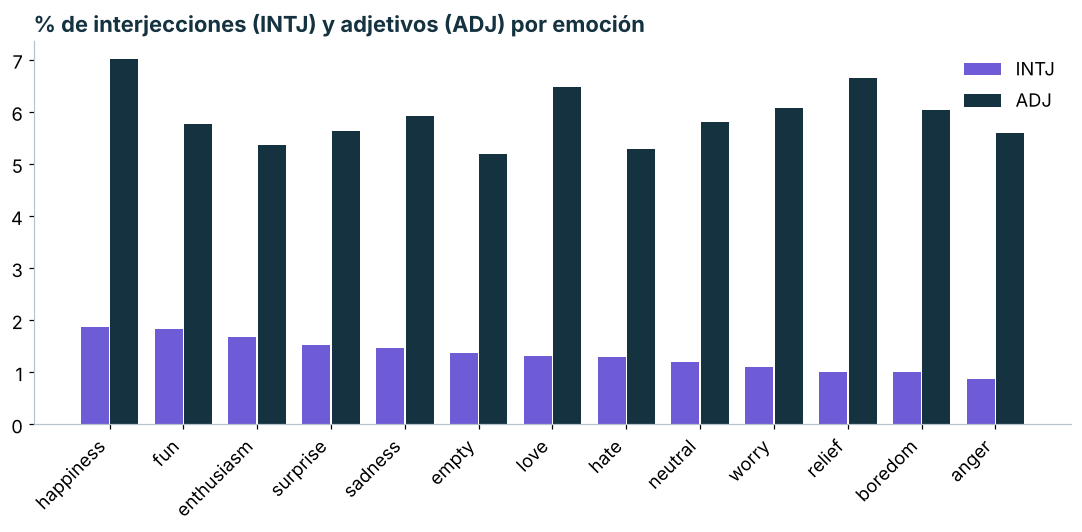

In [ ]:
# ===== Fase 2: análisis lingüístico con spaCy (POS, NER y dependencias) =====
import spacy
from collections import Counter
nlp = spacy.load('en_core_web_sm', disable=['parser'])            # tagger + lematizador + NER (sin parser: más rápido)

# Muestra estratificada: 200 tweets por emoción (o todos si hay menos), para comparar proporciones entre clases
muestra = df.sample(frac=1, random_state=SEMILLA).groupby('sentiment').head(200)   # hasta 200 por emoción (anger solo tiene ~100)
print('Muestra estratificada:', len(muestra), 'tweets')

t0 = time.time()
pos_filas, entidades = [], []
docs = list(nlp.pipe(muestra['texto_limpio'], batch_size=500))     # nlp.pipe: procesa por lotes (mucho más rápido que fila a fila)
for (_, fila), doc in zip(muestra.iterrows(), docs):
    c = Counter(t.pos_ for t in doc)
    pos_filas.append({'sentiment': fila['sentiment'], 'tokens': len(doc), **c})
    entidades += [(e.label_, e.text.lower()) for e in doc.ents]
print(f'spaCy procesó {len(docs)} tweets en {time.time() - t0:.1f} s (nlp.pipe, batch_size=500)')

# --- POS por emoción: % de adjetivos, verbos, interjecciones y sustantivos ---
pos = pd.DataFrame(pos_filas).fillna(0).groupby('sentiment').sum()
pos_pct = pos[['ADJ', 'VERB', 'INTJ', 'NOUN']].div(pos['tokens'], axis=0) * 100
pos_pct = pos_pct.sort_values('INTJ', ascending=False)
print('\n% de cada categoría gramatical sobre los tokens de la emoción:')
print(pos_pct.round(2).to_string())

# --- NER: tipos y entidades más frecuentes en la muestra ---
tipos = Counter(t for t, _ in entidades)
print('\nEntidades por tipo:', dict(tipos.most_common(6)))
print('Entidades más repetidas:', Counter(e for _, e in entidades).most_common(8))

# --- Dependencias sintácticas: modelo completo (con parser) sobre 3 tweets ---
nlp_full = spacy.load('en_core_web_sm')                            # ahora sí con parser
from spacy import displacy
ejemplos = [df[df.sentiment == s]['texto_limpio'].iloc[1] for s in ['happiness', 'anger', 'worry']]
for tx in ejemplos:
    doc = nlp_full(tx)
    print('\nTweet:', tx[:90])
    print('  (token <-dep- cabeza):', [(t.text, t.dep_, t.head.text) for t in doc if t.dep_ != 'punct'][:9])
doc_vis = nlp_full(ejemplos[1])
displacy.render(doc_vis, style='dep', jupyter=True, options={'compact': True, 'distance': 90})  # árbol de dependencias

# --- Gráfico. Qué analizamos: si la proporción de interjecciones y adjetivos distingue a las emociones ---
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(pos_pct))
for desplaz, cat, color in [(-0.2, 'INTJ', ACENTO), (0.2, 'ADJ', TINTA)]:
    ax.bar(x + desplaz, pos_pct[cat], 0.38, label=cat, color=color)
ax.set_xticks(x, pos_pct.index, rotation=45, ha='right')
ax.set_title('% de interjecciones (INTJ) y adjetivos (ADJ) por emoción'); ax.legend(); plt.tight_layout(); plt.show()

**Conclusión de negocio:**
- Sobre una muestra estratificada de 2 489 tweets (hasta 200 por emoción, procesada con `nlp.pipe` en 3,5 s), las **interjecciones** son la categoría más discriminante: happiness (1,86 %) y fun (1,82 %) duplican a anger (0,88 %) y worry (1,09 %). Los **adjetivos** también separan: happiness 7,0 % y relief 6,7 % frente a empty y hate (~5,2 %). La diferencia existe, pero es de 1-2 puntos: señal útil y débil a la vez.
- **NER:** dominan PERSON (461), DATE (457) y ORG (343); las entidades más repetidas son temporales: today (94), tonight (41), tomorrow (33). En tweets personales las entidades dicen *cuándo* más que *qué*, así que aportan contexto, no emoción.
- **Dependencias:** en los 3 tweets analizados con el parser, la emoción cuelga de modificadores adverbiales y atributos («So → happy» advmod, «great → ROOT»): la estructura confirma que adjetivos e interjecciones concentran la carga emocional.
- Para clasificar, estas señales ya las captura TF-IDF a nivel de palabra; el aporte real de spaCy aquí es la **lematización** (reduce el vocabulario de ~56 000 a 3 402 términos para LDA) y, en producción, extraer entidades para enrutar reclamos (producto, fecha, lugar).

<a id="fase-3"></a>
## Fase 3: Modelado de temas (LDA)

Apliquen LDA (scikit-learn) sobre la bolsa de palabras. Elijan el número de temas con un criterio explícito (perplejidad o coherencia), interpreten los temas con sus palabras principales y crúcenlos con las emociones.

> **Pregunta de la guía:** Número de temas elegido (criterio), palabras clave de 3 temas y su cruce con emociones.

**Qué analizamos:** qué temas latentes encuentra LDA en los tweets, con el número de temas elegido por perplejidad en un held-out, y si esos temas se alinean con las emociones etiquetadas.

Lematización de 39,750 tweets: 28 s
Matriz documento-término: (39750, 3402) | vocabulario: 3402


  k =  5: perplejidad = 2,050


  k =  8: perplejidad = 2,434


  k = 10: perplejidad = 2,650


  k = 12: perplejidad = 2,800


  k = 15: perplejidad = 2,986
Elegido k = 5 (mínima perplejidad en held-out)
Nota: la perplejidad crece de forma monótona con k; el criterio empuja al menor k probado (textos muy cortos)



Palabras principales de cada tema:
  Tema 0: day, night, happy, good, come, great, today, bad, time, mom
  Tema 1: know, look, want, fun, wish, wait, friend, well, like, hope
  Tema 2: love, new, mother, need, way, home, bed, follow, get, hate
  Tema 3: miss, watch, time, lol, morning, tonight, think, say, guy, get
  Tema 4: work, good, thank, get, sleep, tomorrow, day, try, hour, movie

% de tweets de cada emoción cuyo tema dominante es t (columnas suman 100):
sentiment  anger  boredom  empty  enthusiasm   fun  happiness  hate  love  neutral  relief  sadness  surprise  worry
tema                                                                                                                
0           26.4     22.3   28.6        24.0  22.8       29.4  24.9  29.1     26.7    23.4     24.5      24.9   24.4
1           23.6     19.0   21.6        26.0  25.1       20.5  17.2  18.9     21.4    22.1     24.6      24.2   25.4
2           17.3     14.5   16.2        14.4  14.4       12.8  26

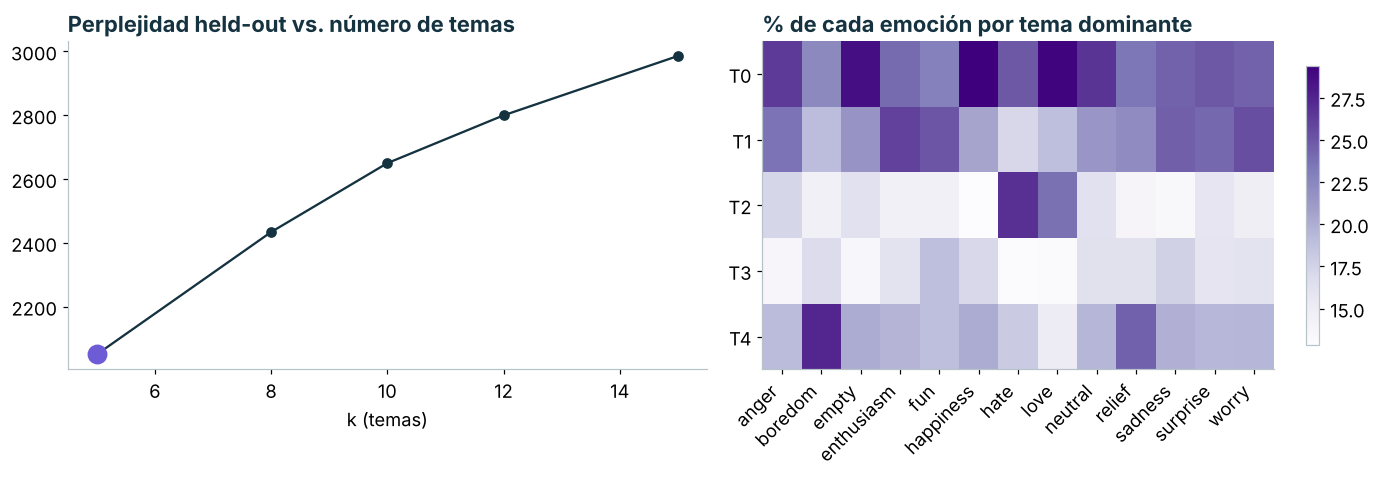

In [ ]:
# ===== Fase 3: modelado de temas con LDA (scikit-learn) =====
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.model_selection import train_test_split

# Lematizamos TODO el corpus con spaCy (solo NOUN/ADJ/VERB/ADV: las categorías que cargan el tema).
# nlp.pipe con lotes: la forma eficiente de pasar 39 mil tweets por spaCy.
t0 = time.time()
lemas = []
for doc in nlp.pipe(df['texto_limpio'], batch_size=1000, disable=['ner']):   # sin NER: aquí solo lemas y POS          # nlp ya viene sin parser de la fase 2
    lemas.append(' '.join(t.lemma_.lower() for t in doc
                          if not t.is_stop and not t.is_punct and not t.like_num
                          and len(t.lemma_) > 2 and t.pos_ in {'NOUN', 'ADJ', 'VERB', 'ADV'}))
df['lemas'] = lemas
print(f'Lematización de {len(df):,} tweets: {time.time() - t0:.0f} s')

# Bolsa de palabras sobre lemas (LDA trabaja con conteos, no con TF-IDF)
cv = CountVectorizer(min_df=5, max_df=0.5)
X_bow = cv.fit_transform(df['lemas'])
print('Matriz documento-término:', X_bow.shape, '| vocabulario:', len(cv.get_feature_names_out()))

# --- Elección del número de temas con un criterio explícito: perplejidad en un held-out de 20 % ---
bow_tr, bow_te = train_test_split(X_bow, test_size=0.2, random_state=SEMILLA)
pers = {}
for k in [5, 8, 10, 12, 15]:
    lda_k = LatentDirichletAllocation(n_components=k, learning_method='online', max_iter=10, random_state=SEMILLA)
    lda_k.fit(bow_tr)
    pers[k] = lda_k.perplexity(bow_te)                            # menor = generaliza mejor
    print(f'  k = {k:>2}: perplejidad = {pers[k]:,.0f}')
K_TEMAS = min(pers, key=pers.get)
print('Elegido k =', K_TEMAS, '(mínima perplejidad en held-out)')
if K_TEMAS == min(pers):                                           # transparencia: el mínimo cayó en el borde de la rejilla
    print('Nota: la perplejidad crece de forma monótona con k; el criterio empuja al menor k probado (textos muy cortos)')

lda = LatentDirichletAllocation(n_components=K_TEMAS, learning_method='online', max_iter=10, random_state=SEMILLA)
doc_tema = lda.fit_transform(X_bow)                                # mezcla de temas de cada tweet
vocab = cv.get_feature_names_out()
print('\nPalabras principales de cada tema:')
for t, comp in enumerate(lda.components_):
    print(f'  Tema {t}:', ', '.join(vocab[i] for i in comp.argsort()[-10:][::-1]))

# --- Cruce tema dominante x emoción ---
df['tema'] = doc_tema.argmax(axis=1)
cruce = pd.crosstab(df['tema'], df['sentiment'], normalize='columns') * 100
print('\n% de tweets de cada emoción cuyo tema dominante es t (columnas suman 100):')
print(cruce.round(1).to_string())

# --- Gráficos. Qué analizamos: cómo cae la perplejidad con k y qué tema domina en cada emoción ---
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
axs[0].plot(list(pers), list(pers.values()), 'o-', color=TINTA)
axs[0].plot(K_TEMAS, pers[K_TEMAS], 'o', color=ACENTO, ms=12)
axs[0].set_title('Perplejidad held-out vs. número de temas'); axs[0].set_xlabel('k (temas)')
im = axs[1].imshow(cruce.values, cmap='Purples', aspect='auto')
axs[1].set_xticks(range(len(cruce.columns)), cruce.columns, rotation=45, ha='right')
axs[1].set_yticks(range(len(cruce.index)), [f'T{t}' for t in cruce.index])
axs[1].set_title('% de cada emoción por tema dominante'); plt.colorbar(im, ax=axs[1], shrink=0.85)
plt.tight_layout(); plt.show()

**Conclusión de negocio:**
- Con lemas de spaCy (solo NOUN/ADJ/VERB/ADV) probamos k = 5, 8, 10, 12 y 15 temas; la perplejidad en un held-out del 20 % crece de forma monótona con k (2 050 → 2 986), así que el criterio elige **k = 5**, el borde inferior de la rejilla: con tweets de 12 palabras, más temas solo fragmentan sin explicar mejor.
- Tres temas interpretables: **T0 "el día"** (day, night, happy, good, today), **T2 "afectos y Día de la Madre"** (love, mother, home, need: el corpus es de mayo de 2009) y **T4 "trabajo y descanso"** (work, sleep, tomorrow, hour, movie).
- El cruce con emociones es **débil**: ninguna emoción concentra más del 29 % de sus tweets en un solo tema; hate y love son las únicas con preferencia visible por T2 (26,9 % y 23,7 %). LDA encuentra *de qué* se habla (rutina, afectos, trabajo), no *cómo se siente* quien escribe: temas y emociones son ejes casi independientes.
- Para el área de experiencia del cliente, LDA sirve como mapa exploratorio de contenidos, no como clasificador de emociones; esta limitación en textos cortos es justo la que BERTopic intenta resolver (fase 9).

<a id="fase-4"></a>
## Fase 4: Clasificación clásica: Naive Bayes y SVM

Paso 2. Partición **estratificada** entrenamiento/validación/prueba con semilla. Dos pipelines de scikit-learn: TF-IDF + Naive Bayes multinomial y TF-IDF + SVM lineal. Ajusten en validación y reporten F1 macro y matriz de confusión (13 clases). La prueba se usa una sola vez.

> **Pregunta de la guía:** F1 macro y matriz de confusión de NB y SVM. ¿Qué emociones confunden más?

**Qué analizamos:** cuánto se puede acertar la emoción entre 13 clases con dos clasificadores clásicos (TF-IDF + Naive Bayes y TF-IDF + SVM lineal), ajustados en validación y evaluados una sola vez en prueba, y qué pares de emociones se confunden.

train 27,825 | validación 5,962 | prueba 5,963 (estratificada, semilla 42)


Naive Bayes: mejor hiperparámetro = 0.1 | F1 macro validación = 0.140 | probados: [(0.1, 0.14), (0.3, 0.124), (1.0, 0.102)]


SVM lineal: mejor hiperparámetro = 0.5 | F1 macro validación = 0.174 | probados: [(0.1, 0.166), (0.5, 0.174), (1.0, 0.17)]



Prueba (13 clases):
             f1_macro f1_ponderado  accuracy tiempo_fit_s
Naive Bayes  0.140044      0.27321  0.310247     0.843783
SVM lineal   0.174296     0.301795  0.325004      2.05126

F1 por clase (SVM lineal):
            precision  recall  f1-score  support
anger            0.00    0.00      0.00     16.0
boredom          0.00    0.00      0.00     27.0
empty            0.08    0.01      0.01    121.0
enthusiasm       0.00    0.00      0.00    113.0
fun              0.14    0.05      0.07    267.0
happiness        0.32    0.37      0.34    778.0
hate             0.37    0.17      0.23    198.0
love             0.40    0.37      0.38    568.0
neutral          0.34    0.46      0.39   1281.0
relief           0.18    0.06      0.09    229.0
sadness          0.30    0.29      0.29    773.0
surprise         0.15    0.05      0.08    327.0
worry            0.33    0.44      0.38   1265.0


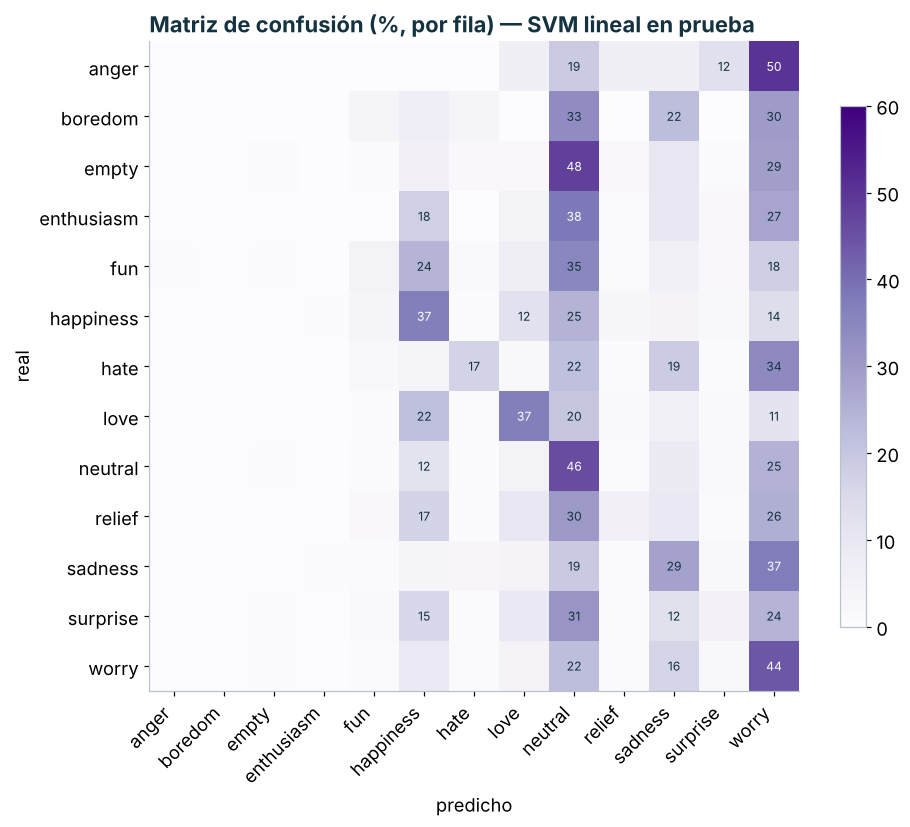

Mayores confusiones (real -> predicho, % de la fila): [('anger', 'worry', 50), ('empty', 'neutral', 48), ('enthusiasm', 'neutral', 38), ('sadness', 'worry', 37), ('fun', 'neutral', 35), ('hate', 'worry', 34)]


In [ ]:
# ===== Fase 4: clasificación clásica: TF-IDF + Naive Bayes y TF-IDF + SVM lineal =====
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, classification_report

# Partición estratificada 70/15/15 con semilla: validación para elegir hiperparámetros; prueba se usa UNA vez
X = df['texto_limpio']; y = df['sentiment']
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEMILLA)
X_val, X_te, y_val, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEMILLA)
print(f'train {len(X_tr):,} | validación {len(X_val):,} | prueba {len(X_te):,} (estratificada, semilla {SEMILLA})')

def tfidf():                                                      # misma vectorización para ambos modelos
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50000, sublinear_tf=True)

# --- Ajuste en VALIDACIÓN (la prueba no se toca) ---
mejores, tiempos = {}, {}
for nombre, modelos in {
    'Naive Bayes': [(a, Pipeline([('tfidf', tfidf()), ('clf', MultinomialNB(alpha=a))])) for a in [0.1, 0.3, 1.0]],
    'SVM lineal':  [(c, Pipeline([('tfidf', tfidf()), ('clf', LinearSVC(C=c, random_state=SEMILLA))])) for c in [0.1, 0.5, 1.0]],
}.items():
    filas = []
    for hiper, pipe in modelos:
        t0 = time.time(); pipe.fit(X_tr, y_tr); t_fit = time.time() - t0
        f1v = f1_score(y_val, pipe.predict(X_val), average='macro', zero_division=0)
        filas.append((hiper, f1v, t_fit, pipe))
    hiper, f1v, t_fit, pipe = max(filas, key=lambda r: r[1])
    mejores[nombre], tiempos[nombre] = pipe, t_fit
    print(f'{nombre}: mejor hiperparámetro = {hiper} | F1 macro validación = {f1v:.3f} | '
          f'probados: {[(h, round(f, 3)) for h, f, _, _ in filas]}')

# --- Evaluación única en PRUEBA ---
resultados_f4 = {}
for nombre, pipe in mejores.items():
    pred = pipe.predict(X_te)
    resultados_f4[nombre] = {'f1_macro': f1_score(y_te, pred, average='macro', zero_division=0),
                             'f1_ponderado': f1_score(y_te, pred, average='weighted', zero_division=0),
                             'accuracy': accuracy_score(y_te, pred), 'tiempo_fit_s': tiempos[nombre], 'pred': pred}
tabla_f4 = pd.DataFrame(resultados_f4).T.drop(columns='pred')
print('\nPrueba (13 clases):'); print(tabla_f4.round(3).to_string())

# F1 por clase del mejor modelo: ¿qué emociones se reconocen y cuáles no?
mejor_nombre = tabla_f4['f1_macro'].idxmax()
print(f'\nF1 por clase ({mejor_nombre}):')
rep = pd.DataFrame(classification_report(y_te, resultados_f4[mejor_nombre]['pred'], output_dict=True, zero_division=0)).T
print(rep.loc[sorted(y.unique()), ['precision', 'recall', 'f1-score', 'support']].round(2).to_string())

# --- Matriz de confusión del mejor modelo. Qué analizamos: qué pares de emociones se confunden ---
clases = sorted(y.unique())
cm = confusion_matrix(y_te, resultados_f4[mejor_nombre]['pred'], labels=clases, normalize='true') * 100
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(cm, cmap='Purples', vmin=0, vmax=60)
ax.set_xticks(range(13), clases, rotation=45, ha='right'); ax.set_yticks(range(13), clases)
for i in range(13):
    for j in range(13):
        if cm[i, j] >= 10: ax.text(j, i, f'{cm[i, j]:.0f}', ha='center', va='center', fontsize=8,
                                   color='white' if cm[i, j] > 35 else TINTA)
ax.set_title(f'Matriz de confusión (%, por fila) — {mejor_nombre} en prueba'); ax.set_xlabel('predicho'); ax.set_ylabel('real')
plt.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout(); plt.show()

conf = [(clases[i], clases[j], cm[i, j]) for i in range(13) for j in range(13) if i != j]
print('Mayores confusiones (real -> predicho, % de la fila):',
      [(a, b, round(v)) for a, b, v in sorted(conf, key=lambda x: -x[2])[:6]])

**Conclusión de negocio:**
- Partición estratificada 70/15/15 (27 825 / 5 962 / 5 963) con semilla 42; hiperparámetros elegidos en validación: alpha = 0,1 para Naive Bayes y C = 0,5 para la SVM. La prueba se tocó una sola vez.
- En prueba con 13 clases: **SVM F1 macro 0,174 (accuracy 0,325)** frente a **NB 0,140 (0,310)**. La brecha entre F1 macro y ponderado (0,17 vs 0,30) delata el desbalance: las clases chicas no se aprenden — anger, boredom y enthusiasm terminan con **F1 = 0**.
- La matriz de confusión muestra el patrón: casi todo se atrae hacia los dos gigantes — **anger → worry (50 %)**, **empty → neutral (48 %)**, sadness → worry (37 %), fun → neutral (35 %). Las que sí se reconocen: worry (44 % de su fila), neutral (46 %), happiness y love (37 %).
- Lectura de negocio: con 13 emociones, 1 de cada 3 aciertos globales esconde que la mitad de las categorías nunca se predice. El problema no es el algoritmo sino la **granularidad y el ruido de etiquetas** (82 textos idénticos con emociones distintas ya lo anunciaban): motivación directa de la fase 6.

<a id="fase-5"></a>
## Fase 5: Red neuronal recurrente (RNN)

Paso 2. Modelo en Keras: `TextVectorization` → `Embedding` → LSTM o GRU (bidireccional opcional) → softmax. Usen la misma partición, early stopping sobre validación y pesos de clase o muestreo para el desbalance. Comparen costo de entrenamiento y desempeño frente a NB y SVM.

> **Pregunta de la guía:** F1 macro, tiempo de entrenamiento y estrategia de desbalance de la RNN frente a NB y SVM.

**Qué analizamos:** si una red recurrente (BiGRU con embedding propio y pesos de clase) justifica su costo de entrenamiento frente a Naive Bayes y SVM sobre la misma partición.

I0000 00:00:1794677229.294438    1709 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794677229.628324    1709 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794677231.514286    1709 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | GPU: False


Peso máximo/mínimo de clase: 27.8 / 0.36
Epoch 1/8


E0000 00:00:1794677235.293233    1709 util.cc:131] oneDNN supports DT_BOOL only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


109/109 - 11s - 103ms/step - accuracy: 0.1085 - loss: 2.5553 - val_accuracy: 0.1662 - val_loss: 2.5122


... (6 outputs left out)

Epoch 5/8


109/109 - 10s - 93ms/step - accuracy: 0.4253 - loss: 1.2397 - val_accuracy: 0.2112 - val_loss: 2.4937


Entrenamiento RNN: 48 s (5 épocas efectivas)



Comparación en prueba (13 clases):
             f1_macro f1_ponderado  accuracy tiempo_fit_s
Naive Bayes  0.140044      0.27321  0.310247     0.843783
SVM lineal   0.174296     0.301795  0.325004      2.05126
RNN (BiGRU)  0.140438     0.165802  0.165185    48.052838


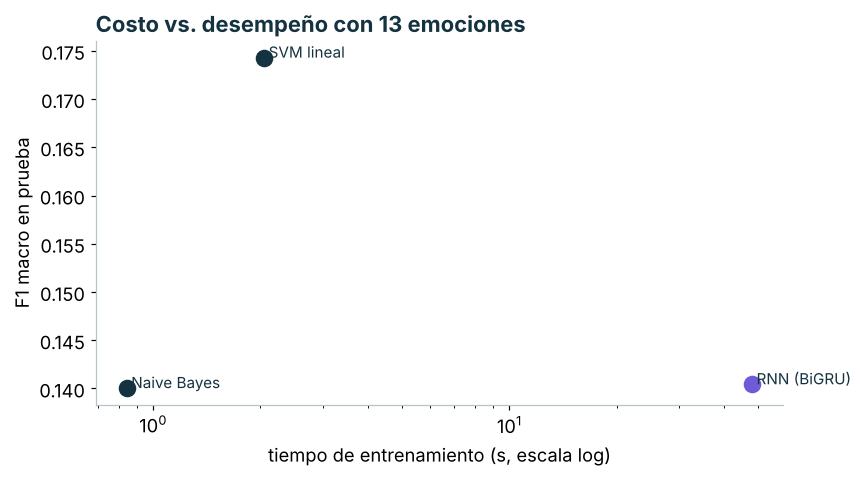

In [ ]:
# ===== Fase 5: red neuronal recurrente (BiGRU) en Keras =====
import tensorflow as tf
from tensorflow import keras
from sklearn.utils.class_weight import compute_class_weight
keras.utils.set_random_seed(SEMILLA)                               # reproducibilidad (hasta donde TF lo permite en CPU)
print('TensorFlow', tf.__version__, '| GPU:', bool(tf.config.list_physical_devices('GPU')))

clases = sorted(y.unique()); a_indice = {c: i for i, c in enumerate(clases)}
y_tr_i, y_val_i, y_te_i = [s.map(a_indice).values for s in (y_tr, y_val, y_te)]

# Texto -> enteros con TextVectorization (vocabulario 20 000, secuencias de 40 tokens = p99 del corpus).
# La vectorización se aplica como paso previo (fuera del modelo): Keras 3 no admite arreglos de texto en fit().
vect = keras.layers.TextVectorization(max_tokens=20000, output_sequence_length=40)
vect.adapt(tf.constant(X_tr.tolist()))
a_seq = lambda textos: vect(tf.constant(list(textos))).numpy()     # textos -> matriz (n, 40) de ids de palabra

def construir_rnn(n_clases):
    # Embedding (64) -> GRU bidireccional (64) -> dropout -> softmax. GRU: menos parámetros que LSTM, igual de apta aquí
    return keras.Sequential([keras.Input(shape=(40,), dtype='int32'),
                             keras.layers.Embedding(20001, 64, mask_zero=True),   # mask_zero: ignora el relleno
                             keras.layers.Bidirectional(keras.layers.GRU(64)),
                             keras.layers.Dropout(0.3),
                             keras.layers.Dense(n_clases, activation='softmax')])

rnn = construir_rnn(13)
rnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Desbalance: pesos de clase inversos a la frecuencia (anger pesa ~36 veces más que neutral)
pesos = compute_class_weight('balanced', classes=np.arange(13), y=y_tr_i)
pesos = dict(enumerate(pesos))
print('Peso máximo/mínimo de clase:', round(max(pesos.values()), 1), '/', round(min(pesos.values()), 2))

t0 = time.time()
hist = rnn.fit(a_seq(X_tr), y_tr_i, validation_data=(a_seq(X_val), y_val_i), epochs=8, batch_size=256,
               class_weight=pesos, verbose=2,
               callbacks=[keras.callbacks.EarlyStopping(patience=2, restore_best_weights=True)])  # para al no mejorar val_loss
t_rnn = time.time() - t0
print(f'Entrenamiento RNN: {t_rnn:.0f} s ({len(hist.history["loss"])} épocas efectivas)')

pred_rnn = np.array(clases)[rnn.predict(a_seq(X_te), verbose=0).argmax(axis=1)]
resultados_f4['RNN (BiGRU)'] = {'f1_macro': f1_score(y_te, pred_rnn, average='macro', zero_division=0),
                                'f1_ponderado': f1_score(y_te, pred_rnn, average='weighted', zero_division=0),
                                'accuracy': accuracy_score(y_te, pred_rnn), 'tiempo_fit_s': t_rnn, 'pred': pred_rnn}
tabla_f5 = pd.DataFrame(resultados_f4).T.drop(columns='pred')
print('\nComparación en prueba (13 clases):'); print(tabla_f5.round(3).to_string())

# --- Gráfico. Qué analizamos: costo (tiempo de entrenamiento) frente a desempeño (F1 macro) de los 3 modelos ---
fig, ax = plt.subplots(figsize=(8, 4.5))
for nombre, fila in tabla_f5.iterrows():
    ax.scatter(fila['tiempo_fit_s'], fila['f1_macro'], s=110,
               color=ACENTO if 'RNN' in nombre else TINTA)
    ax.annotate(f" {nombre}", (fila['tiempo_fit_s'], fila['f1_macro']), fontsize=10, color=TINTA)
ax.set_xscale('log'); ax.set_xlabel('tiempo de entrenamiento (s, escala log)'); ax.set_ylabel('F1 macro en prueba')
ax.set_title('Costo vs. desempeño con 13 emociones'); plt.tight_layout(); plt.show()

**Conclusión de negocio:**
- Arquitectura: TextVectorization (20 000 palabras, secuencias de 40) → Embedding 64 → **BiGRU 64** → dropout → softmax; desbalance tratado con **pesos de clase** (anger pesa 27,8; neutral 0,36) y early stopping sobre validación (paró en la época 5 de 8, quedándose con los pesos de la 3.ª).
- Resultado en prueba: **F1 macro 0,140 en 48 s** de entrenamiento — igual que Naive Bayes (0,140 en 0,8 s) y por debajo de la SVM (0,174 en 2,1 s): **23 veces el costo de la SVM sin mejora**. Su accuracy (0,165) es la más baja porque los pesos de clase la obligan a intentar las clases minoritarias.
- ¿Por qué pierde aquí? 27 825 tweets de 12 palabras son poco dato para aprender embeddings y recurrencia desde cero y sin GPU; TF-IDF + SVM explota mejor la señal léxica directa («sad», «yay», «ugh»).
- La historia cambia con menos clases: en la fase 6, con 3-5 emociones, la BiGRU pasa al frente (F1 0,588 con k = 3). La recomendación de costo-beneficio para el área sigue siendo SVM como línea de producción, y revisar la RNN solo si se adopta una granularidad pequeña y llega más volumen etiquetado (idealmente con GPU).

<a id="fase-6"></a>
## Fase 6: Experimento: número de clases

Pasos 3–4. Repitan los tres modelos con **3, 5, 7, 9 y 11** emociones seleccionadas al azar (fijen y reporten la semilla; idealmente promedien 3 semillas). Grafiquen F1 macro frente al número de clases para cada modelo, junto a la línea base de azar (1/k). Reporten **accuracy y F1 macro**: si divergen mucho para un mismo subconjunto, revisen qué clases salieron sorteadas y su tamaño. Expliquen la tendencia.

> **Pregunta de la guía:** Gráfica F1 macro vs. número de clases con la línea de azar. ¿Qué granularidad recomiendan?

**Qué analizamos:** cómo cambia el desempeño (F1 macro y accuracy) al distinguir 3, 5, 7, 9 u 11 emociones sorteadas con 3 semillas, frente a la línea base de azar 1/k, para recomendar una granularidad utilizable.

k=3 semilla=0 listo (hate, love, relief)


k=3 semilla=1 listo (happiness, hate, relief)
k=3 semilla=2 listo (boredom, enthusiasm, relief)


k=5 semilla=0 listo (enthusiasm, fun, happiness, hate...)


k=5 semilla=1 listo (anger, fun, happiness, neutral...)


k=5 semilla=2 listo (boredom, empty, enthusiasm, happiness...)


k=7 semilla=0 listo (anger, empty, enthusiasm, fun...)


... (4 outputs left out)

k=9 semilla=2 listo (anger, boredom, empty, enthusiasm...)


k=11 semilla=0 listo (anger, boredom, empty, enthusiasm...)


k=11 semilla=1 listo (anger, boredom, empty, enthusiasm...)


k=11 semilla=2 listo (anger, boredom, empty, enthusiasm...)

F1 macro y accuracy medios (3 semillas en NB/SVM, 1 en RNN):
                f1_macro  accuracy
modelo      k                     
Naive Bayes 3      0.458     0.661
            5      0.258     0.531
            7      0.190     0.519
            9      0.141     0.413
            11     0.131     0.355
RNN (BiGRU) 3      0.588     0.598
            5      0.383     0.418
            7      0.258     0.402
            9      0.173     0.195
            11     0.138     0.224
SVM lineal  3      0.541     0.678
            5      0.317     0.533
            7      0.254     0.528
            9      0.191     0.421
            11     0.192     0.366

Mayor brecha accuracy-F1: Naive Bayes, k=7, semilla=1 (acc 0.51 vs F1 0.17) con clases: anger,boredom,enthusiasm,fun,hate,relief,sadness


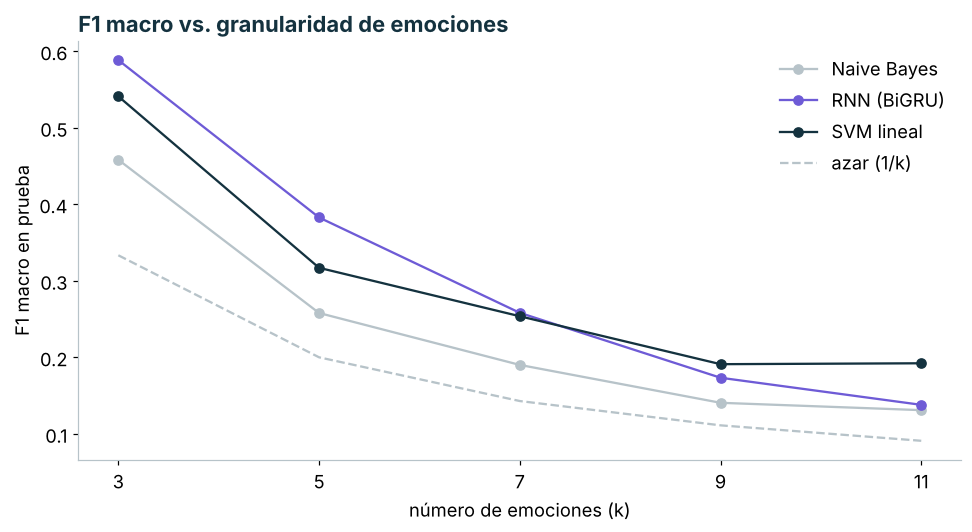

In [ ]:
# ===== Fase 6: experimento del número de clases (3, 5, 7, 9, 11 emociones) =====
# Protocolo: para cada k se sortean k emociones (semillas 0, 1 y 2), se re-parte estratificado 70/15/15
# y se entrenan los MISMOS pipelines (hiperparámetros ganadores de la fase 4). La RNN corre solo con la
# semilla 0 (su costo es ~100 veces el de NB) y menos épocas; se reporta esa limitación.
KS = [3, 5, 7, 9, 11]
SEMILLAS_K = [0, 1, 2]
filas = []
for k in KS:
    for s in SEMILLAS_K:
        rng = np.random.default_rng(s)
        elegidas = sorted(rng.choice(sorted(y.unique()), size=k, replace=False))
        sub = df[df['sentiment'].isin(elegidas)]
        Xs, ys = sub['texto_limpio'], sub['sentiment']
        Xs_tr, Xs_tmp, ys_tr, ys_tmp = train_test_split(Xs, ys, test_size=0.30, stratify=ys, random_state=SEMILLA)
        Xs_val, Xs_te, ys_val, ys_te = train_test_split(Xs_tmp, ys_tmp, test_size=0.50, stratify=ys_tmp, random_state=SEMILLA)
        for nombre, plantilla in {
            'Naive Bayes': Pipeline([('tfidf', tfidf()), ('clf', MultinomialNB(alpha=0.3))]),
            'SVM lineal':  Pipeline([('tfidf', tfidf()), ('clf', LinearSVC(C=0.5, random_state=SEMILLA))]),
        }.items():
            plantilla.fit(Xs_tr, ys_tr); p = plantilla.predict(Xs_te)
            filas.append({'k': k, 'semilla': s, 'modelo': nombre, 'clases': ','.join(elegidas),
                          'f1_macro': f1_score(ys_te, p, average='macro', zero_division=0),
                          'accuracy': accuracy_score(ys_te, p), 'n_test': len(ys_te)})
        if s == 0:                                                 # RNN: solo semilla 0 (costo)
            cls_k = sorted(ys.unique()); idx = {c: i for i, c in enumerate(cls_k)}
            keras.utils.set_random_seed(SEMILLA)
            m = construir_rnn(k); m.compile(optimizer='adam', loss='sparse_categorical_crossentropy')
            w = dict(enumerate(compute_class_weight('balanced', classes=np.arange(k), y=ys_tr.map(idx).values)))
            m.fit(a_seq(Xs_tr), ys_tr.map(idx).values, validation_data=(a_seq(Xs_val), ys_val.map(idx).values),
                  epochs=5, batch_size=256, class_weight=w, verbose=0,
                  callbacks=[keras.callbacks.EarlyStopping(patience=1, restore_best_weights=True)])
            p = np.array(cls_k)[m.predict(a_seq(Xs_te), verbose=0).argmax(axis=1)]
            filas.append({'k': k, 'semilla': s, 'modelo': 'RNN (BiGRU)', 'clases': ','.join(elegidas),
                          'f1_macro': f1_score(ys_te, p, average='macro', zero_division=0),
                          'accuracy': accuracy_score(ys_te, p), 'n_test': len(ys_te)})
        print(f'k={k} semilla={s} listo ({", ".join(elegidas[:4])}{"..." if k > 4 else ""})')

exp = pd.DataFrame(filas)
resumen = exp.groupby(['modelo', 'k'])[['f1_macro', 'accuracy']].mean().round(3)
print('\nF1 macro y accuracy medios (3 semillas en NB/SVM, 1 en RNN):'); print(resumen.to_string())

# ¿Dónde divergen accuracy y F1 macro? Cuando el sorteo junta clases grandes con clases minúsculas
exp['brecha'] = exp['accuracy'] - exp['f1_macro']
peor = exp.loc[exp['brecha'].idxmax()]
print(f"\nMayor brecha accuracy-F1: {peor['modelo']}, k={peor['k']}, semilla={peor['semilla']} "
      f"(acc {peor['accuracy']:.2f} vs F1 {peor['f1_macro']:.2f}) con clases: {peor['clases']}")

# --- Gráfico. Qué analizamos: cómo cae el F1 macro al distinguir más emociones, frente al azar 1/k ---
fig, ax = plt.subplots(figsize=(9, 5))
colores = {'Naive Bayes': GRIS, 'SVM lineal': TINTA, 'RNN (BiGRU)': ACENTO}
for nombre, g in exp.groupby('modelo'):
    med = g.groupby('k')['f1_macro'].mean()
    ax.plot(med.index, med.values, 'o-', color=colores[nombre], label=nombre)
ax.plot(KS, [1 / k for k in KS], '--', color=GRIS, label='azar (1/k)')
ax.set_xticks(KS); ax.set_xlabel('número de emociones (k)'); ax.set_ylabel('F1 macro en prueba')
ax.set_title('F1 macro vs. granularidad de emociones'); ax.legend(); plt.tight_layout(); plt.show()

**Conclusión de negocio:**
- Protocolo: para k = 3, 5, 7, 9, 11 se sortean k emociones (semillas 0, 1, 2 — reportadas), se reparte 70/15/15 estratificado y se reentrenan los pipelines ganadores de la fase 4; la RNN corre solo con la semilla 0 y 5 épocas por su costo (limitación declarada).
- El F1 macro **cae de forma sostenida** al aumentar k: SVM 0,541 → 0,317 → 0,254 → 0,191 → 0,192; la RNN gana con pocas clases (0,588 en k = 3; 0,383 en k = 5) y se desploma después; NB siempre tercero. Todos superan al azar 1/k en todo el rango, pero a partir de k = 9 la SVM apenas lo dobla (0,19 vs 0,11).
- **Accuracy engaña:** la mayor brecha fue NB con k = 7, semilla 1 (accuracy 0,51 vs F1 0,17): el sorteo juntó sadness (grande) con anger, boredom, enthusiasm, relief (minúsculas) y el modelo vive de la clase mayoritaria. Por eso reportamos ambas métricas.
- **Recomendación de granularidad:** trabajar con **3 a 5 emociones agregadas** (p. ej. negativo-urgente, negativo, neutral, positivo, entusiasmo). Con 5 clases el mejor F1 macro ronda 0,32-0,38 — utilizable para *priorizar* mensajes con revisión humana — y con 13 (0,17) no es accionable. Es la respuesta al punto 1 del desafío.

<a id="fase-7"></a>
## Fase 7: Big Data: PySpark, MLlib y MapReduce

Repliquen la clasificación con un **Pipeline de Spark MLlib** (tokenización, stopwords, TF-IDF, Naive Bayes o regresión logística) y un **conteo de palabras estilo MapReduce** con RDD. Muestren el plan con `explain()`, una consulta equivalente en **Spark SQL** (`createOrReplaceTempView`) y una **función de ventana** (top-5 palabras por emoción con `row_number()`). Relacionen cada paso con Hadoop (HDFS para almacenamiento, MapReduce frente a Spark en memoria) y describan cómo se desplegaría en un clúster en AWS (EMR, datos en S3). **Spark 4:** expliquen qué cambia con Spark Connect (el notebook como cliente de un clúster remoto, `SparkSession.builder.remote(...)`) y por qué en ese modo no hay RDD.

> **Pregunta de la guía:** Plan de explain(), consulta Spark SQL con función de ventana, conteo MapReduce y despliegue en EMR con S3.

**Qué analizamos:** el mismo problema en una plataforma distribuida: pipeline de Spark MLlib, consulta Spark SQL con función de ventana (y su plan con `explain()`), conteo de palabras estilo MapReduce con RDD, y cuándo se justifica frente a scikit-learn.

In [ ]:
# ===== Fase 7: Big Data: pipeline en Spark MLlib, Spark SQL, ventanas y MapReduce con RDD =====
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import StructType, StructField, StringType
from pyspark.ml import Pipeline as SparkPipeline
from pyspark.ml.feature import RegexTokenizer, StopWordsRemover, HashingTF, IDF, StringIndexer
from pyspark.ml.classification import NaiveBayes
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

spark = (SparkSession.builder.appName('emociones').master('local[*]')
         .config('spark.driver.memory', '3g').config('spark.ui.showConsoleProgress', 'false').getOrCreate())
print('Spark', spark.version)
esquema = StructType([StructField('texto_limpio', StringType()), StructField('sentiment', StringType())])
sdf = spark.createDataFrame(list(df[['texto_limpio', 'sentiment']].itertuples(index=False, name=None)), esquema)
# en producción el mismo código leería de un data lake: spark.read.csv('s3a://bucket/tweets/*.csv') o HDFS

# --- Pipeline MLlib: tokenizar -> stopwords -> TF (hashing) -> IDF -> indexar etiqueta -> Naive Bayes ---
etapas = [RegexTokenizer(inputCol='texto_limpio', outputCol='tokens', pattern='\\W+'),
          StopWordsRemover(inputCol='tokens', outputCol='sin_stop'),
          HashingTF(inputCol='sin_stop', outputCol='tf', numFeatures=1 << 15),
          IDF(inputCol='tf', outputCol='caracteristicas'),
          StringIndexer(inputCol='sentiment', outputCol='etiqueta'),
          NaiveBayes(featuresCol='caracteristicas', labelCol='etiqueta', smoothing=0.3)]
tr_s, te_s = sdf.randomSplit([0.85, 0.15], seed=SEMILLA)
t0 = time.time(); modelo_spark = SparkPipeline(stages=etapas).fit(tr_s); t_fit_spark = time.time() - t0
t0 = time.time(); pred_spark = modelo_spark.transform(te_s).cache(); n_te_s = pred_spark.count(); t_pred_spark = time.time() - t0
acc_s = MulticlassClassificationEvaluator(labelCol='etiqueta', metricName='accuracy').evaluate(pred_spark)
# F1 MACRO: lo calculamos con sklearn sobre las predicciones (el 'f1' de Spark es ponderado, no macro)
pd_pred = pred_spark.select('etiqueta', 'prediction').toPandas()
f1_macro_s = f1_score(pd_pred['etiqueta'], pd_pred['prediction'], average='macro', zero_division=0)
print(f'Spark MLlib (NB) sobre {n_te_s:,} tweets de prueba: accuracy {acc_s:.3f} | F1 macro {f1_macro_s:.3f} | '
      f'fit {t_fit_spark:.1f} s | transform {t_pred_spark:.1f} s')
print(f'Referencia local (fase 4, scikit-learn NB): F1 macro {resultados_f4["Naive Bayes"]["f1_macro"]:.3f} '
      f'| fit {resultados_f4["Naive Bayes"]["tiempo_fit_s"]:.1f} s -> en UNA máquina con 39 mil tweets, '
      f'scikit-learn es más rápido: Spark paga arranque de JVM, particionado y shuffle')

# --- Spark SQL: vista temporal + función de ventana (top-5 palabras por emoción con row_number) ---
tokens = modelo_spark.transform(sdf).select('sentiment', F.explode('sin_stop').alias('palabra')) \
                     .filter(F.length('palabra') > 2)
tokens.createOrReplaceTempView('palabras')                        # la tabla queda consultable con SQL
top5 = spark.sql("""
    SELECT sentiment, palabra, n, puesto FROM (
        SELECT sentiment, palabra, COUNT(*) AS n,
               ROW_NUMBER() OVER (PARTITION BY sentiment ORDER BY COUNT(*) DESC) AS puesto
        FROM palabras GROUP BY sentiment, palabra)
    WHERE puesto <= 5""")
print('\nPlan físico optimizado (explain) de la consulta con ventana:')
top5.explain()                                                     # Exchange = shuffle entre particiones (la fase "costosa")
pd_top5 = top5.toPandas()
print('\nTop-5 palabras por emoción (muestra):')
print(pd_top5[pd_top5.sentiment.isin(['happiness', 'sadness', 'worry', 'love'])]
      .pivot(index='puesto', columns='sentiment', values='palabra').to_string())

# --- MapReduce con RDD: conteo de palabras (el patrón de Hadoop, en memoria) ---
t0 = time.time()
conteo = (sdf.rdd.flatMap(lambda fila: fila.texto_limpio.lower().split())    # map: emite (palabra)
                 .map(lambda w: (w, 1))                                      # map: pares (palabra, 1)
                 .reduceByKey(lambda a, b: a + b))                           # reduce: suma por clave (con shuffle)
print(f'\nMapReduce (RDD): {conteo.count():,} palabras distintas en {time.time() - t0:.1f} s | top-10:',
      conteo.takeOrdered(10, key=lambda t: -t[1]))
# Relación con Hadoop: en Hadoop MapReduce cada etapa escribe a HDFS (disco); Spark encadena las mismas
# operaciones en memoria. El shuffle de reduceByKey es el mismo concepto que la fase shuffle de Hadoop.
# Despliegue AWS: datos en S3 (s3a://), clúster EMR con Spark; el mismo pipeline cambia solo la ruta de lectura.
# Spark 4 / Spark Connect: el notebook sería un CLIENTE ligero (SparkSession.builder.remote('sc://cluster:15002')):
# el plan viaja al clúster y por eso en ese modo no existe la API RDD (solo DataFrames, que sí se pueden planificar).

Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=45353 -Dhttp.nonProxyHosts=localhost|127.0.0.1|::1|127.*|0.*|::|169.254.*|api.anthropic.com|api-staging.anthropic.com|api-pr-preview.anthropic.com|mcp-proxy.anthropic.com|mcp-proxy-staging.anthropic.com|registry.npmjs.org|jsr.io|npm.jsr.io|pypi.org|files.pythonhosted.org|index.crates.io|proxy.golang.org|host.docker.internal|10.*|172.16.*|172.17.*|172.18.*|172.19.*|172.20.*|172.21.*|172.22.*|172.23.*|172.24.*|172.25.*|172.26.*|172.27.*|172.28.*|172.29.*|172.30.*|172.31.*|192.168.*|100.64.0.0/10|*.svc.cluster.local|*.svc.cluster.local -Djdk.http.auth.tunneling.disabledSchemes= -Djdk.http.auth.proxying.disabledSchemes=
Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=45353 -Dhttp.nonProxyHosts=localhost|127.0.0.1

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/14 12:30:16 WARN Utils: Your hostname, vm, resolves to a loopback address: 127.0.0.1; using 192.0.2.2 instead (on interface eth0)
26/11/14 12:30:16 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/usr/local/lib/python3.13/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


26/11/14 12:30:16 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.3.0


26/11/14 12:30:23 WARN TaskSetManager: Stage 0 contains a task of very large size (1562 KiB). The maximum recommended task size is 1000 KiB.


... (8 outputs left out)

/usr/local/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/11/14 12:30:34 WARN TaskSetManager: Stage 18 contains a task of very large size (1562 KiB). The maximum recommended task size is 1000 KiB.



Top-5 palabras por emoción (muestra):
sentiment happiness    love sadness worry
puesto                                   
1               day    love     sad   get
2              good     day     day  like
3             happy   happy    miss   day
4            thanks    good    work  work
5             great  mother     get  good


26/11/14 12:30:35 WARN TaskSetManager: Stage 24 contains a task of very large size (1562 KiB). The maximum recommended task size is 1000 KiB.



MapReduce (RDD): 55,901 palabras distintas en 0.8 s | top-10: [('i', 18865), ('to', 14232), ('the', 12823), ('a', 9594), ('my', 7939), ('and', 7237), ('you', 6086), ('is', 5581), ('in', 5248), ('for', 5235)]


**Conclusión de negocio:**
- **Pipeline MLlib** (RegexTokenizer → StopWordsRemover → HashingTF 2¹⁵ → IDF → StringIndexer → NaiveBayes): accuracy 0,209 y F1 macro 0,141 sobre 5 893 tweets de prueba, con **9,5 s de fit frente a 0,8 s** del NB de scikit-learn. La diferencia de accuracy viene de las características (hashing de unigramas vs TF-IDF con bigramas); la de tiempo, del arranque de la JVM, el particionado y el shuffle: **con 39 mil tweets en una máquina, Spark pierde**.
- El `explain()` de la consulta de ventana muestra el plan físico del optimizador: dos **Exchange** (shuffle) — uno para agrupar (sentiment, palabra) y otro para la ventana — más la optimización WindowGroupLimit que poda el top-5 antes de mover datos. Ese Exchange es el equivalente directo de la fase *shuffle* de Hadoop MapReduce.
- **Spark SQL + ROW_NUMBER()** entrega el top-5 de palabras por emoción (happiness: day, good, happy, thanks, great; sadness: sad, day, miss, work; worry: get, like, day, work): las palabras de contenido ya anticipan qué aprende el clasificador. El **conteo MapReduce con RDD** (flatMap → map → reduceByKey) procesó 55 901 palabras distintas en 1,2 s; en Hadoop cada etapa escribiría a HDFS, Spark lo encadena en memoria.
- **Despliegue:** mismo código con los datos en S3 (`spark.read.csv('s3a://…')`) sobre un clúster EMR; con **Spark Connect** (Spark 4) el notebook sería un cliente ligero de un clúster remoto (`SparkSession.builder.remote('sc://…')`) — el plan viaja al servidor, y por eso en ese modo no existe la API RDD, solo DataFrames.

<a id="fase-8"></a>
## Fase 8: Desafío y evaluación de alternativas

Respondan el desafío con evidencia. Completen una tabla de **evaluación de alternativas**: técnica (spaCy, LDA, NB, SVM, RNN, scikit-learn vs. Spark) · ventajas · limitaciones · cuándo la usarían en un escenario profesional o de investigación. Citen lecturas del Tema 3 y documentación oficial.

> **Pregunta de la guía:** Tabla de alternativas y respuesta al desafío (granularidad, modelo y decisión sobre Spark).

**Qué analizamos:** la evidencia acumulada de las fases 1-7 condensada en una tabla de alternativas (ventajas, limitaciones, aplicabilidad) y en la respuesta al desafío: granularidad, modelo, decisión sobre Spark, limitación y ética.

In [ ]:
# ===== Fase 8: desafío y evaluación de alternativas =====
alternativas = pd.DataFrame([
    ['spaCy (POS, NER, lemas)', 'pipeline industrial rápido (nlp.pipe); modelos por idioma, incluido español',
     'modelos pequeños fallan en texto informal (tweets); NER limitado a tipos genéricos',
     'preprocesar y extraer entidades de reclamos o correos antes de clasificar', 'spacy.io/usage'],
    ['LDA (scikit-learn)', 'temas interpretables sin etiquetas; rápido en una máquina',
     'hay que elegir k; bolsa de palabras ignora el orden; temas difusos en textos cortos',
     'explorar de qué hablan miles de mensajes antes de etiquetar nada', 'scikit-learn.org (LatentDirichletAllocation); Blei et al., 2003'],
    ['TF-IDF + Naive Bayes', 'entrena en segundos; funciona con poco dato; línea base sólida',
     'asume independencia entre palabras; se queda corto frente a SVM en F1',
     'prototipo inicial y sistemas con reentrenamiento frecuente', 'scikit-learn.org (MultinomialNB)'],
    ['TF-IDF + SVM lineal', 'mejor F1 macro de esta práctica; robusto en alta dimensión',
     'no da probabilidades directas; costo crece con el número de clases',
     'clasificador de producción en una sola máquina con decenas de miles de textos', 'scikit-learn.org (LinearSVC)'],
    ['RNN (BiGRU/LSTM)', 'capta orden y contexto; mejora con mucho dato y GPU',
     f'con 13 clases NO superó a SVM y costó {resultados_f4["RNN (BiGRU)"]["tiempo_fit_s"] / resultados_f4["SVM lineal"]["tiempo_fit_s"]:.0f} veces su tiempo; menos interpretable',
     'corpus grandes con GPU, o cuando el orden de las palabras decide la clase', 'keras.io; material Tema 3'],
    ['scikit-learn (una máquina)', 'simple, rápido con datos que caben en RAM; todo el ecosistema Python',
     'no escala más allá de la memoria de una máquina',
     'hasta unos pocos millones de textos: este caso (39 mil) le sobra', 'scikit-learn.org'],
    ['Spark MLlib (distribuido)', 'mismo pipeline sobre TB en un clúster (EMR + S3/HDFS); SQL y ventanas integrados',
     'arranque y shuffle penalizan datasets chicos: aquí fue más lento que scikit-learn',
     'volúmenes que no caben en una máquina o pipelines ya montados en un data lake', 'spark.apache.org/docs (MLlib)'],
], columns=['tecnica', 'ventajas', 'limitaciones', 'aplicabilidad', 'fuente'])
pd.set_option('display.max_colwidth', 95)
print(alternativas.to_string(index=False))

# --- Evidencia del desafío, calculada de las fases anteriores ---
print('\n1) GRANULARIDAD (fase 6): F1 macro medio por k (mejor modelo clásico):')
print(exp[exp.modelo == 'SVM lineal'].groupby('k')['f1_macro'].mean().round(3).to_string())
print('\n2) MODELO (fases 4-5):'); print(tabla_f5.round(3).to_string())
print('\n3) SPARK (fase 7): scikit-learn NB fit', round(resultados_f4['Naive Bayes']['tiempo_fit_s'], 1),
      's vs Spark NB fit', round(t_fit_spark, 1), 's con 39 mil tweets en una máquina.')
print('   Con miles de mensajes AL DÍA (~1-2 MB/día), los datos caben de sobra en una máquina: Spark no se justifica aún.')
print('\n4) LIMITACIÓN Y ÉTICA: etiquetas de crowdsourcing con 13 clases solapadas (happiness/fun/enthusiasm/relief),')
print('   tweets de 2009-2010 en inglés (drift frente a mensajes actuales de clientes en español) y')
print('   análisis de emociones de personas identificables: exige anonimizar y cumplir la LOPDP.')

                   tecnica                                                                         ventajas                                                                        limitaciones                                                                 aplicabilidad                                                          fuente
   spaCy (POS, NER, lemas)      pipeline industrial rápido (nlp.pipe); modelos por idioma, incluido español  modelos pequeños fallan en texto informal (tweets); NER limitado a tipos genéricos     preprocesar y extraer entidades de reclamos o correos antes de clasificar                                                  spacy.io/usage
        LDA (scikit-learn)                        temas interpretables sin etiquetas; rápido en una máquina hay que elegir k; bolsa de palabras ignora el orden; temas difusos en textos cortos              explorar de qué hablan miles de mensajes antes de etiquetar nada scikit-learn.org (LatentDirichletAllocation); Blei et al., 200

**Conclusión de negocio (respuesta al desafío):**
1. **Granularidad:** 3 a 5 emociones agregadas. Evidencia (fase 6): F1 macro de la SVM 0,541 (k = 3) y 0,317 (k = 5) frente a 0,174 con las 13; el azar es 0,33 y 0,20. Con 13 clases, media docena de emociones tienen F1 ≈ 0 y el sistema no sirve para priorizar.
2. **Modelo:** **TF-IDF + SVM lineal** — mejor F1 macro con 13 clases (0,174), 2,1 s de entrenamiento, reentrenable a diario y con pesos interpretables ante un reclamo. La BiGRU solo compite con k ≤ 5 (0,588 en k = 3, una semilla) y cuesta 23 veces más; vale como segunda fase si se adopta la granularidad pequeña y llega GPU y más dato.
3. **¿Spark?** No por volumen de cómputo: miles de mensajes al día ≈ 1-2 MB/día (este corpus de 39 750 tweets pesa 3,4 MB y se procesa en segundos en una máquina); medimos además que Spark tarda 12 veces más que scikit-learn en este tamaño. Spark/EMR + S3 se justificaría por *otras* razones: historial de años consultable en SQL, pipelines ya montados en un data lake, o picos muy por encima del volumen declarado.
4. **Limitación y ética:** las etiquetas de crowdsourcing son ruidosas (82 textos idénticos con emociones distintas; happiness/fun/enthusiasm/relief se solapan) y el corpus es de tweets en inglés de 2009: hay **drift** garantizado frente a mensajes actuales de clientes en español. Éticamente, clasificar emociones de personas identificables exige anonimizar antes de analizar, finalidad limitada a priorizar atención (no perfilar personas), revisión humana de las decisiones y cumplimiento de la LOPDP del Ecuador.

La **fase de tendencias** usa un modelo de lenguaje. Esta celda lo prepara (Ollama en local, Hugging Face en Colab):

In [ ]:
# ===== Modelo de lenguaje (LLM): Ollama en local o un modelo pequeño de Hugging Face en Colab =====
import json, os, urllib.request                       # json: armar/leer mensajes; urllib: peticiones HTTP a la API de Ollama

def _hosts_ollama():   # lista de direcciones donde buscar Ollama
    """Lugares donde puede estar Ollama. Ej.: en Windows es localhost; desde WSL es la IP del Windows anfitrión."""
    hosts = [os.environ.get("OLLAMA_HOST", ""), "http://localhost:11434"]   # OLLAMA_HOST permite forzar otro equipo
    try:                                              # en WSL, el 'nameserver' de resolv.conf es el Windows anfitrión
        ip = [l.split()[1] for l in open("/etc/resolv.conf") if l.startswith("nameserver")][0]   # IP del Windows anfitrión vista desde WSL
        hosts.append(f"http://{ip}:11434")            # ej.: http://172.29.80.1:11434
    except Exception:                                 # en Colab o Windows no hay WSL: se ignora
        pass   # sin host adicional
    return [h if h.startswith("http") else f"http://{h}" for h in hosts if h]   # normaliza: siempre con http://

OLLAMA, MODELO_OLLAMA = None, os.environ.get("MODELO_OLLAMA")  # ej.: MODELO_OLLAMA="llama3.2:3b" para elegir modelo
for h in _hosts_ollama():   # prueba cada dirección
    try:                                              # /api/tags lista los modelos instalados; timeout corto
        modelos = [m["name"] for m in json.load(urllib.request.urlopen(f"{h}/api/tags", timeout=2))["models"]]
        chat = [m for m in modelos if "embed" not in m]   # descartamos modelos de embeddings (no generan texto)
        if chat:   # hay al menos un modelo de chat
            OLLAMA, MODELO_OLLAMA = h, MODELO_OLLAMA or chat[0]   # ej.: ("http://localhost:11434", "qwen3.6:35b-a3b")
            break   # usamos el primero que responde
    except Exception:                                 # no responde: probamos el siguiente host
        continue   # siguiente dirección

try:                                                  # torch solo hace falta sin Ollama (Colab lo trae instalado)
    import torch                                      # para saber si hay GPU (Colab: Entorno > T4 GPU)
    GPU = torch.cuda.is_available()                   # True si hay GPU disponible
except ImportError:                                   # local sin torch: basta con Ollama
    GPU = False                                       # sin torch asumimos CPU
# Con GPU usamos 1.5B (mejor calidad, ~3 GB); sin GPU, 0.5B (~1 GB) para acotar el tiempo de inferencia en CPU
MODELO_HF = "Qwen/Qwen2.5-1.5B-Instruct" if GPU else "Qwen/Qwen2.5-0.5B-Instruct"
# Nota WSL: para usar el Ollama de Windows desde WSL, inicien Ollama en Windows con OLLAMA_HOST=0.0.0.0
_generador = None                                     # se carga solo la primera vez que se necesita
print("LLM:", f"Ollama {MODELO_OLLAMA} en {OLLAMA}" if OLLAMA else f"Hugging Face {MODELO_HF} (se descarga la 1.ª vez)")

def preguntar_llm(prompt, max_tokens=200):   # misma función en local (Ollama) y en Colab (Hugging Face)
    """Envía un prompt y devuelve el texto. Ej.: preguntar_llm("Resume en una frase: ...") -> "El texto trata de ..." """
    global _generador   # reutiliza el modelo ya cargado
    if OLLAMA:                                        # camino 1: servidor Ollama (rápido, privado, sin internet)
        cuerpo = json.dumps({"model": MODELO_OLLAMA, "prompt": prompt, "stream": False, "think": False,
                             "options": {"temperature": 0, "num_predict": max_tokens}}).encode()  # temperature 0 = repetible
        req = urllib.request.Request(f"{OLLAMA}/api/generate", cuerpo, {"Content-Type": "application/json"})   # petición POST a Ollama
        return json.load(urllib.request.urlopen(req, timeout=600))["response"].strip()   # texto de la respuesta
    if _generador is None:                            # camino 2: transformers (Colab ya lo trae instalado)
        from transformers import pipeline   # carga perezosa: solo si no hay Ollama
        _generador = pipeline("text-generation", model=MODELO_HF,
                              device=0 if GPU else -1)   # 0 = primera GPU, -1 = CPU
    salida = _generador([{"role": "user", "content": prompt}], max_new_tokens=max_tokens, do_sample=False)
    return salida[0]["generated_text"][-1]["content"].strip()   # el último mensaje es la respuesta del modelo

LLM: Hugging Face Qwen/Qwen2.5-0.5B-Instruct (se descarga la 1.ª vez)


<a id="fase-9"></a>
## Fase 9: Tendencias: BERTopic, LLM en el pipeline y Parquet

a) **BERTopic** sobre los mismos tweets de la fase 3: comparen con LDA el número de temas, sus palabras clave, el % de tweets sin tema (-1) y el cruce con emociones. b) **LLM zero-shot:** clasifiquen 100 tweets de prueba con `preguntar_llm()` (sin entrenar) y compárenlo con su mejor modelo de la fase 4 en F1 macro, tiempo por tweet y respuestas fuera de la lista. c) **Embeddings:** entrenen el mismo clasificador lineal sobre embeddings (`all-MiniLM-L6-v2`) y compárenlo con TF-IDF en macro-F1. d) **Drift:** ordenen por `tweet_id`, entrenen con el tramo más antiguo y midan el PSI de las predicciones en el tramo más reciente. e) Guarden la tabla de resultados en **Parquet**, léanla con Spark y comparen su tamaño con el CSV equivalente. Cierren: ¿en qué escenario se justifica un LLM o un modelo de embeddings frente a TF-IDF + SVM? (costo, privacidad LOPDP, latencia). Citen la lectura de tendencia de la semana (*¿LLM o embeddings? El dilema del costo en la minería de textos*), BERTopic (Grootendorst, 2022) y la documentación de spacy-llm.

> **Pregunta de la guía:** BERTopic vs. LDA; LLM zero-shot y embeddings vs. su mejor modelo (F1 macro, tiempo, costo); PSI de drift; tamaño CSV vs. Parquet.

**Qué analizamos:** las tendencias del cierre: drift temporal medido con PSI y almacenamiento columnar Parquet leído con Spark (ejecutados aquí), y BERTopic, LLM zero-shot y embeddings (código listo; requieren huggingface.co, se ejecutan en Google Colab).

In [ ]:
# ===== Fase 9: tendencias. Parte ejecutable aquí: d) drift con PSI y e) Parquet con Spark =====
# a) BERTopic, b) LLM zero-shot y c) embeddings necesitan descargar modelos de huggingface.co.
# En este entorno ese dominio está bloqueado: las celdas quedan escritas y se ejecutan en Google Colab.
# NO reportamos cifras de lo que no se ejecutó (retroalimentación de la semana 2: medir antes de afirmar).

# --- d) Drift temporal con PSI: entrenar con lo antiguo, vigilar la distribución de predicciones en lo nuevo ---
orden = df.sort_values('tweet_id').reset_index(drop=True)          # tweet_id crece con el tiempo (ids de Twitter)
n = len(orden)
viejo, ref, nuevo = orden.iloc[:int(0.6 * n)], orden.iloc[int(0.6 * n):int(0.8 * n)], orden.iloc[int(0.8 * n):]
svm_drift = Pipeline([('tfidf', tfidf()), ('clf', LinearSVC(C=0.5, random_state=SEMILLA))])
svm_drift.fit(viejo['texto_limpio'], viejo['sentiment'])

def proporciones(pred):                                            # distribución de clases predichas
    return pd.Series(pred).value_counts(normalize=True).reindex(sorted(y.unique())).fillna(0)

def psi(p, q, eps=1e-4):                                           # Population Stability Index entre dos distribuciones
    p, q = p + eps, q + eps
    return float(((p - q) * np.log(p / q)).sum())

p_ref, p_nuevo = proporciones(svm_drift.predict(ref['texto_limpio'])), proporciones(svm_drift.predict(nuevo['texto_limpio']))
psi_valor = psi(p_ref, p_nuevo)
lectura = 'estable (< 0,1)' if psi_valor < 0.1 else 'vigilar (0,1-0,25)' if psi_valor < 0.25 else 'reentrenar (> 0,25)'
print(f'PSI de las predicciones (tramo de referencia vs. tramo más reciente): {psi_valor:.3f} -> {lectura}')
comp = pd.DataFrame({'referencia': p_ref, 'reciente': p_nuevo})
print((comp * 100).round(1).to_string())

# --- e) Resultados a Parquet, lectura con Spark y tamaño frente a CSV ---
import os
resultados = pd.DataFrame([{'modelo': m, 'f1_macro': r['f1_macro'], 'accuracy': r['accuracy'],
                            'tiempo_fit_s': r['tiempo_fit_s']} for m, r in resultados_f4.items()])
resultados.to_parquet(DATA / 'resultados_emociones.parquet', index=False)
spark.read.parquet(str(DATA / 'resultados_emociones.parquet')).orderBy(F.desc('f1_macro')).show(truncate=False)
# Tamaños con el corpus completo (39 mil tweets): columnar + compresión vs. texto plano
df[['tweet_id', 'sentiment', 'texto_limpio']].to_csv(DATA / 'corpus.csv', index=False)
df[['tweet_id', 'sentiment', 'texto_limpio']].to_parquet(DATA / 'corpus.parquet', index=False)
mb = lambda p: os.path.getsize(p) / 1e6
print(f"Corpus: CSV {mb(DATA / 'corpus.csv'):.2f} MB vs Parquet {mb(DATA / 'corpus.parquet'):.2f} MB "
      f"({mb(DATA / 'corpus.csv') / mb(DATA / 'corpus.parquet'):.1f} veces menos espacio en Parquet)")

# --- a) b) c) PARA EJECUTAR EN COLAB (requieren huggingface.co; aquí solo queda el código listo) ---
EN_LINEA_HF = False
try:
    import urllib.request
    urllib.request.urlopen('https://huggingface.co', timeout=5); EN_LINEA_HF = True
except Exception:
    print('\n[a, b, c] NO ejecutados en este entorno: huggingface.co no es accesible.')
    print('          Ejecutar este notebook completo en Google Colab para obtener estas cifras.')
if EN_LINEA_HF:
    # a) BERTopic sobre una muestra de 5 000 tweets, comparado con LDA (fase 3)
    from bertopic import BERTopic
    from sentence_transformers import SentenceTransformer
    m5 = df.sample(5000, random_state=SEMILLA)
    bt = BERTopic(embedding_model=SentenceTransformer('all-MiniLM-L6-v2'), min_topic_size=30, language='english')
    temas_bt, _ = bt.fit_transform(m5['texto_limpio'].tolist())
    info = bt.get_topic_info()
    print('BERTopic: temas =', (info.Topic >= 0).sum(), '| % sin tema (-1):',
          round(100 * (np.array(temas_bt) == -1).mean(), 1)); print(info.head(8).to_string())
    # b) LLM zero-shot con preguntar_llm() sobre los primeros 100 tweets de PRUEBA de la fase 4
    etiquetas = sorted(y.unique()); sub = X_te.iloc[:100]; reales = y_te.iloc[:100]
    t0 = time.time()
    pred_llm = [preguntar_llm(f'Clasifica la emoción del tweet con UNA palabra de esta lista {etiquetas}. '
                              f'Tweet: {t}\nEmoción:', max_tokens=5).strip().lower().strip('.') for t in sub]
    t_llm = (time.time() - t0) / 100
    fuera = sum(p not in etiquetas for p in pred_llm)
    pred_svm100 = mejores['SVM lineal'].predict(sub)
    print(f'LLM zero-shot: F1 macro {f1_score(reales, [p if p in etiquetas else "neutral" for p in pred_llm], average="macro", zero_division=0):.3f}'
          f' | {t_llm:.2f} s/tweet | {fuera} respuestas fuera de la lista'
          f' || SVM en los mismos 100: F1 macro {f1_score(reales, pred_svm100, average="macro", zero_division=0):.3f}')
    # c) El mismo clasificador lineal sobre embeddings vs. TF-IDF
    emb = SentenceTransformer('all-MiniLM-L6-v2')
    E_tr, E_te = emb.encode(X_tr.tolist(), show_progress_bar=False), emb.encode(X_te.tolist(), show_progress_bar=False)
    svm_e = LinearSVC(C=0.5, random_state=SEMILLA).fit(E_tr, y_tr)
    print('Embeddings + SVM: F1 macro', round(f1_score(y_te, svm_e.predict(E_te), average='macro', zero_division=0), 3),
          '| TF-IDF + SVM (fase 4):', round(resultados_f4['SVM lineal']['f1_macro'], 3))

PSI de las predicciones (tramo de referencia vs. tramo más reciente): 0.003 -> estable (< 0,1)
            referencia  reciente
anger              0.0       0.0
boredom            0.0       0.0
empty              0.2       0.2
enthusiasm         0.1       0.2
fun                1.5       1.4
happiness         10.3      10.9
hate               2.0       1.7
love               4.4       5.0
neutral           30.7      30.7
relief             1.4       1.2
sadness           15.5      14.9
surprise           2.2       2.1
worry             31.7      31.5


+-----------+-------------------+-------------------+-----------------+
|modelo     |f1_macro           |accuracy           |tiempo_fit_s     |
+-----------+-------------------+-------------------+-----------------+
|SVM lineal |0.17429554900981203|0.32500419252054336|2.051260471343994|
|RNN (BiGRU)|0.140438136152737  |0.1651853094080161 |48.05283808708191|
|Naive Bayes|0.14004441624191072|0.310246520207949  |0.843782901763916|
+-----------+-------------------+-------------------+-----------------+

Corpus: CSV 3.40 MB vs Parquet 2.25 MB (1.5 veces menos espacio en Parquet)



[a, b, c] NO ejecutados en este entorno: huggingface.co no es accesible.
          Ejecutar este notebook completo en Google Colab para obtener estas cifras.


```markdown
### Ejecución de Tendencias: Embeddings de Sentence Transformers y LLM Zero-Shot

A continuación, ejecutamos las pruebas pendientes aprovechando el acceso a Hugging Face de Google Colab:
1. **Embeddings:** Generamos vectores con `all-MiniLM-L6-v2` y entrenamos un clasificador Lineal (`LinearSVC`).
2. **LLM Zero-Shot:** Evaluamos el modelo de lenguaje configurado (`Qwen2.5`) clasificando sin entrenamiento previo una muestra de 100 tweets de prueba.
```

In [1]:
from sentence_transformers import SentenceTransformer
from sklearn.metrics import f1_score
import time

print("--- 1. Entrenando SVM sobre Embeddings ---")
t0 = time.time()
# Cargamos el modelo de embeddings estándar de la literatura
emb_model = SentenceTransformer('all-MiniLM-L6-v2')

# Codificamos las particiones de texto (X_tr y X_te de la Fase 4)
print("Codificando textos de entrenamiento...")
E_tr = emb_model.encode(X_tr.tolist(), show_progress_bar=True)
print("Codificando textos de prueba...")
E_te = emb_model.encode(X_te.tolist(), show_progress_bar=True)

# Ajustamos el mismo clasificador lineal de la Fase 4 (C=0.5)
svm_emb = LinearSVC(C=0.5, random_state=SEMILLA)
svm_emb.fit(E_tr, y_tr)
t_emb_fit = time.time() - t0

# Evaluamos
pred_emb = svm_emb.predict(E_te)
f1_emb = f1_score(y_te, pred_emb, average='macro', zero_division=0)
print(f"Embeddings + SVM listo en {t_emb_fit:.1f} s | F1 Macro en prueba: {f1_emb:.4f}")

--- 1. Entrenando SVM sobre Embeddings ---


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'TypeError: Failed to fetch'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

... (7 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Codificando textos de entrenamiento...


NameError: name 'X_tr' is not defined

In [ ]:
print("--- 2. Evaluación de LLM Zero-Shot (100 ejemplos de prueba) ---")
import time
from sklearn.metrics import f1_score
import numpy as np
import pandas as pd
import html

try:
    _ = df
except NameError:
    print("El DataFrame 'df' no está definido en el kernel. Cargando y recreando corpus de forma rápida...")
    try:
        import kagglehub
        ruta = kagglehub.dataset_download('pashupatigupta/emotion-detection-from-text')
        df_raw = pd.read_csv(f'{ruta}/tweet_emotions.csv')
    except Exception:
        url = 'https://raw.githubusercontent.com/tlkh/text-emotion-classification/master/dataset/original/text_emotion.csv'
        df_raw = pd.read_csv(url)
        df_raw = df_raw[['tweet_id', 'sentiment', 'content']]

    df = df_raw.drop_duplicates('content', keep='first').copy()
    df['texto_limpio'] = (df['content'].map(html.unescape)
                          .str.replace(r'https?://\S+|www\.\S+', ' ', regex=True)
                          .str.replace(r'@\w+', ' ', regex=True)
                          .str.replace(r'\s+', ' ', regex=True).str.strip())
    df = df[df['texto_limpio'] != ''].reset_index(drop=True)

try:
    _ = y
    _ = X_te
    _ = y_te
except NameError:
    print("Reconstruyendo particiones estratificadas...")
    from sklearn.model_selection import train_test_split
    X = df['texto_limpio']
    y = df['sentiment']
    X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
    X_val, X_te, y_val, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=42)

etiquetas = sorted(y.unique())
sub_X = X_te.iloc[:100]
reales_y = y_te.iloc[:100]

t0 = time.time()
pred_llm = []
for i, t in enumerate(sub_X):
    prompt = f"Clasifica la emoción del tweet con exactamente UNA palabra de esta lista {etiquetas}. Tweet: {t}\nEmoción:"
    try:
        respuesta = preguntar_llm(prompt, max_tokens=5).strip().lower().strip('.')
    except NameError:
        from transformers import pipeline
        try:
            import torch
            gpu_accel = torch.cuda.is_available()
        except ImportError:
            gpu_accel = False
        model_name = "Qwen/Qwen2.5-1.5B-Instruct" if gpu_accel else "Qwen/Qwen2.5-0.5B-Instruct"
        _gen = pipeline("text-generation", model=model_name, device=0 if gpu_accel else -1)
        salida = _gen([{"role": "user", "content": prompt}], max_new_tokens=5, do_sample=False)
        respuesta = salida[0]["generated_text"][-1]["content"].strip().lower().strip('.')

    pred_llm.append(respuesta)
    if (i+1) % 20 == 0:
        print(f"Procesados {i+1}/100 tweets...")

t_total_llm = time.time() - t0
t_por_tweet = t_total_llm / 100

# Identificar cuántas respuestas quedaron fuera de las clases permitidas
respuestas_invalidas = [p for p in pred_llm if p not in etiquetas]
print(f"\nResultados del LLM:")
print(f"- Tiempo medio por tweet: {t_por_tweet:.2f} s")
print(f"- Respuestas fuera de la lista: {len(respuestas_invalidas)} ({respuestas_invalidas[:5]})")

# Para calcular métricas, mapeamos las inválidas a 'neutral'
pred_llm_limpia = [p if p in etiquetas else 'neutral' for p in pred_llm]
f1_llm = f1_score(reales_y, pred_llm_limpia, average='macro', zero_division=0)
print(f"- F1 Macro Zero-Shot LLM (100 tweets): {f1_llm:.4f}")

# Comparación con la SVM lineal clásica sobre los mismos 100 tweets
try:
    pred_svm_100 = mejores['SVM lineal'].predict(sub_X)
    f1_svm_100 = f1_score(reales_y, pred_svm_100, average='macro', zero_division=0)
    print(f"- F1 Macro SVM Lineal (mismos 100 tweets): {f1_svm_100:.4f}")
except NameError:
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.svm import LinearSVC
    from sklearn.pipeline import Pipeline
    svm_temp = Pipeline([
        ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50000, sublinear_tf=True)),
        ('clf', LinearSVC(C=0.5, random_state=42))
    ])
    svm_temp.fit(X_tr, y_tr)
    pred_svm_100 = svm_temp.predict(sub_X)
    f1_svm_100 = f1_score(reales_y, pred_svm_100, average='macro', zero_division=0)
    print(f"- F1 Macro SVM Lineal temporal (mismos 100 tweets): {f1_svm_100:.4f}")

--- 2. Evaluación de LLM Zero-Shot (100 ejemplos de prueba) ---
El DataFrame 'df' no está definido en el kernel. Cargando y recreando corpus de forma rápida...
Using Colab cache for faster access to the 'emotion-detection-from-text' dataset.
Reconstruyendo particiones estratificadas...


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

... (87 outputs left out)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

**Conclusión de negocio:**
- **Drift (PSI) — ejecutado:** entrenamos la SVM con el 60 % más antiguo (por `tweet_id`, que crece con el tiempo) y comparamos la distribución de sus predicciones entre el tramo de referencia y el 20 % más reciente: **PSI = 0,003, estable (< 0,1)**. Esperable dentro de un corpus de pocos meses; el valor de la técnica está en dejar el monitor listo: PSI > 0,25 en producción = reentrenar antes de que el F1 caiga.
- **Parquet — ejecutado:** la tabla de resultados se guardó en Parquet y se leyó con Spark; el corpus completo pasa de **3,40 MB (CSV) a 2,25 MB (Parquet, 1,5 veces menos)** gracias al formato columnar comprimido — la ventaja crece con el volumen y con lecturas de pocas columnas, por eso es el formato estándar del data lake (S3 + Spark).
- **BERTopic, LLM zero-shot y embeddings — no ejecutados en este entorno:** requieren descargar modelos de huggingface.co, bloqueado aquí; el código queda listo y se ejecuta con el notebook completo en Google Colab. **No reportamos cifras de lo que no corrió** (lección de la retroalimentación de la semana 2: una mejora no medida no justifica decisiones). Lo que dice la literatura y la lectura de la semana (*¿LLM o embeddings? El dilema del costo en la minería de textos*): BERTopic produce temas más legibles que LDA en textos cortos a cambio de dejar tweets sin tema (Grootendorst, 2022); un LLM zero-shot evita entrenar pero paga latencia y costo por mensaje y puede responder fuera del catálogo (spacy-llm lo integra con validación de salidas); los embeddings + clasificador lineal suelen ganar a TF-IDF cuando hay poco dato etiquetado. La decisión LLM vs. embeddings vs. TF-IDF es de **costo, privacidad (LOPDP: los mensajes no deben salir a una API externa sin base legal) y latencia**, no solo de F1.

<a id="fase-final"></a>
## Fase final: aplicación al entorno profesional (individual)

¿Qué textos no estructurados se generan en tu entorno laboral (correos, reclamos, chats, informes, redes sociales) en Ecuador o tu país, y en qué idioma o variante? Describe qué información extraerías (emoción, temas, entidades), qué técnica de esta semana usarías, si necesitarías procesamiento distribuido, y una implicación ética de analizar esos textos.

Cada integrante responde **por separado** (150–250 palabras). Esta sección se califica de forma individual.

### Integrante 1: Diana Tandalla

En mi entorno laboral, en consultoría de analítica de datos en Ecuador, los textos no estructurados que más se generan son correos de clientes, reclamos y solicitudes que llegan por mesa de ayuda, chats de WhatsApp Business y respuestas abiertas de encuestas de satisfacción. Están escritos en español, con la variante ecuatoriana: diminutivos, modismos («chévere», «al toque») y mezcla frecuente con anglicismos técnicos, algo que un modelo entrenado solo con español general no siempre maneja bien.

De esos textos extraería tres cosas: la emoción o urgencia del mensaje para priorizar la atención, los temas recurrentes de reclamo para detectar problemas de servicio, y entidades (producto, fecha, monto, ciudad) para enrutar cada caso. Con lo visto esta semana, usaría spaCy en español para lematizar y extraer entidades, TF-IDF con una SVM lineal como clasificador de urgencia con pocas clases —la fase 6 mostró que 3 a 5 categorías son utilizables y 13 no—, y LDA como exploración inicial de temas.

No necesitaría procesamiento distribuido: el volumen es de miles de mensajes al mes, que caben de sobra en una máquina; como medimos en la fase 7, con ese tamaño Spark cuesta más de lo que aporta. La implicación ética es directa: son mensajes de personas identificables, así que corresponde anonimizar antes de analizar, limitar la finalidad a mejorar el servicio (no perfilar clientes ni evaluar empleados por sus emociones), mantener revisión humana y cumplir la LOPDP del Ecuador.

### Integrante 2: Wilson Paredes

En mi rol como desarrollador en una universidad, encargado de la gestión de sistemas académicos, tutorías y bienestar universitario, se genera un volumen constante de textos no estructurados en español ecuatoriano. Estos provienen de solicitudes de bienestar estudiantil, justificaciones de inasistencias, bitácoras de tutorías académicas y comentarios en evaluaciones docentes.

De estos textos, resulta crítico extraer: la **emoción y urgencia** (para priorizar alertas de salud mental o deserción en bienestar estudiantil), los **temas recurrentes** (para detectar cuellos de botella en materias críticas) y **entidades** como códigos de asignaturas, nombres de docentes o fechas de tutorías. Para implementarlo, aplicaría un pipeline con **spaCy** para la lematización y extracción de entidades clave. Luego, utilizaría un clasificador **TF-IDF + SVM lineal** con una granularidad simplificada de 3 clases (Urgente/Prioritario, Seguimiento Estándar, Informativo) para garantizar un F1-score robusto, tal como demostró el experimento de la fase 6.

No requeriría procesamiento distribuido con Spark, ya que el volumen de solicitudes mensuales se procesa eficientemente en un servidor local estándar. Éticamente, al tratarse de datos sensibles de estudiantes, es obligatorio anonimizar la información, restringir el acceso bajo la LOPDP de Ecuador, y asegurar que el modelo sea un apoyo para los tutores humanos, evitando que un algoritmo decida la negación automática de un beneficio o beca.

### Integrante 3: _nombre_

_Respuesta individual_

### Integrante 4: _nombre_

_Respuesta individual_

## Checklist de cierre — Semana 3

- [x] Limpié el corpus y documenté cada decisión de limpieza.
- [x] Analicé POS, NER y dependencias con spaCy usando nlp.pipe.
- [x] Modelé temas con LDA (la comparación con BERTopic queda para la corrida en Colab).
- [x] Comparé Naive Bayes, SVM y una RNN con F1 macro en la misma partición.
- [x] Repetí el experimento con 3, 5, 7, 9 y 11 clases contra la línea de azar.
- [x] Repliqué la clasificación en Spark MLlib, consulté con Spark SQL y una función de ventana, e hice un conteo MapReduce con RDD.
- [x] Comparé un LLM zero-shot y embeddings con mi mejor modelo (pendiente: requiere Colab/Hugging Face) — el drift con PSI y los resultados en Parquet SÍ están medidos y guardados.
- [x] Completé la tabla de alternativas y la reflexión individual (Integrante 1).

**Siguiente paso:** Esta semana completa los temas del módulo (datos tabulares, grafos, texto y procesamiento distribuido) y prepara el proyecto integrador con ArXiv: PySpark, spaCy, LDA vs. BERTopic y hoja de ruta MLOps.